# Human Validation der QA-basierten Faktenretention

**Reproduzierbare Analyse der historischen Validierung, der Scorer-Kalibrierung und des Transfers zum Hauptexperiment.**

## Ergebnisüberblick

- Sieben Rückgaben umfassen **204 vollständige Bewertungen von 420 möglichen Kombinationen**; pro QA-Fall liegen zwei bis fünf gültige Stimmen vor.
- **172/204 Fragenqualitätsurteile (84,3 %) sind `good`**. Das sagt etwas über die ausgewählten QA-Einheiten, nicht über die Vollständigkeit oder Relevanz aller extrahierten Fakten.
- Auf dem eindeutigen Drei-Klassen-Konsensset steigt die Übereinstimmung von **32/52 (61,5 %) auf 41/52 (78,8 %)**, wenn dieselben historischen Antworten mit dem eingefrorenen kalibrierten Scorer bewertet werden. Die historische Auswertung einschließlich alphabetisch aufgelöster Ties ergibt 33/58 → 42/58.
- Diese Verbesserung ist ein **Kalibrierungsergebnis auf wiederverwendeten Fällen**. Sie ist keine unabhängige Schätzung der Leistung auf neuen Artikeln.
- Die menschliche Antwortlabel-Reliabilität ist begrenzt (**nominales Alpha = 0,297**). Die drei eindeutigen menschlichen `unsupported`-Fälle werden auch nach Kalibrierung als `lost` klassifiziert; eine valide Halluzinationsmessung ist damit nicht belegt.
- Der September-Antworterabgleich verwendet dieselben menschlichen Urteile. Sein archivierter Nenner 54 schließt zwei `unclear`-Konsensfälle ein; ein harmonisierter Drei-Klassen-Vergleich verwendet 52 Fälle.

Die Reihenfolge folgt der Messlogik: **Was wurde geprüft? → Wie belastbar sind die Urteile? → Wo scheitert der ursprüngliche Scorer? → Was verändert die Kalibrierung? → Was folgt für das Hauptexperiment?**

## 1. Kontext, Untersuchungsfragen und Methoden

Das Hauptexperiment untersucht Faktenretention bei rekursiver Zusammenfassung von CNN/DailyMail-Artikeln über 500, 300, 150 und 75 Wörter. Ein QA-System beantwortet feste, aus dem Original abgeleitete Fragen anhand jeder Zusammenfassung. Damit können Fehler an mehreren Stellen entstehen: Fakt-/Fragengenerierung, Zusammenfassung, QA-Antworter und Antwortvergleich.

Die **Faktenrelevanzvalidierung** im bestehenden Notebook prüft die Auswahl des Messgegenstands. Dieses Notebook prüft dagegen die **Brauchbarkeit der QA-Einheiten und die Antwortklassifikation**. Beide Prüfungen sind komplementär; gute Fragen garantieren weder relevante Fakten noch korrekte automatische Antwortlabels.

### 1.1 Design und Annotationsmaterial

Die 60 Einheiten stammen aus sechs Artikeln des Mai-Piloten `20260516T134205Z_qwen30_10_article_kpi_test`: Qwen3:30b-Zusammenfassungen, drei historische Promptmethoden und vier Kompressionsstufen; ursprünglicher QA-Antworter `glm-4.7-flash:latest`. Die Auswahl war **deterministisch und quotiert**: je 20 automatische Ausgangslabels, je 20 Methoden und je 15 Wortstufen. Artikel und Entitätstypen wurden zusätzlich ausbalanciert. Es sind 25 einzigartige kanonische Fragen, teilweise über Methoden/Stufen wiederholt.

Sichtbar waren Artikelanfang (bis 120 Wörter), Quellenstelle, Fakt, Frage, Referenzantwort, Zusammenfassung, Modellantwort und Modellbegründung; außerdem Methode und Zielwortzahl. Nur das automatische Ausgangslabel war verborgen. Die Begründung wurde in der App bei bestimmten Urteilen eingeblendet; in der CSV war sie verfügbar. Eine vollständige Verblindung gegenüber dem Modell ist daher nicht belegt. Maßgeblich war die **Zusammenfassung**, nicht allein die Wahrheit im Original.

| Dimension | Labels | Interpretation |
|---|---|---|
| Fragenqualität | good / partial / bad / unclear | Verständlichkeit, Quellenbezug und Referenzantwort |
| Antwortbewertung | retained / lost / unsupported / unclear | Erhaltene Information, fehlende Information, unbelegte/widersprüchliche Antwort oder Unsicherheit |

### 1.2 Auswertungssätze und Annahmen

1. **Einzelurteile:** gültige Labels; leere/ungültige Eingaben bleiben fehlend. `unclear` ist ein tatsächlich vergebenes Urteil.
2. **Historische Replikation (58):** Konsens als häufigstes Label, Ties alphabetisch entschieden; `unclear`-Konsens ausgeschlossen.
3. **Primärer eindeutiger Konsens (52):** zusätzlich sechs Antwortlabel-Ties ausgeschlossen. „Konsens“ bezeichnet eine eindeutige Pluralität; eine absolute Mehrheit wird gesondert geprüft.
4. **Sensitivität:** absolute Mehrheit, gültige Fragenqualität, nur vollständig annotierende Personen, Ausschluss einzelner Personen/Artikel, gleiche Gewichtung von Artikeln bzw. einzigartigen Fakten.

Diese Auswertungshierarchie ist eine nachträgliche Entscheidung für die vorliegende Reanalyse; sie war nicht präregistriert. Ein separater Trainings- oder Testdatensatz ist nicht dokumentiert.

Antwortlabels sind **nominal**, ohne sinnvolle Rangordnung. Deshalb werden ungewichtetes Cohen-Kappa und nominales Krippendorff-Alpha verwendet. Die Messgrößen sind deskriptiv. Sechs Artikel und wiederholte Fragen rechtfertigen keine Behandlung der 204 Urteile oder 60 Fälle als unabhängige Stichprobe. Es werden keine Fall-Bootstrap-Konfidenzintervalle und keine Signifikanzbehauptungen erzeugt. Leave-one-out-Spannen sind Stabilitätsdiagnostik, keine Konfidenzintervalle.

### 1.3 Ausführung und Quellen

Das Notebook benötigt Python ≥3.10, pandas, NumPy, Matplotlib, scikit-learn und IPython. Die mitgelieferten Quellen befinden sich in `human_validation_qa_daten/`; alle Berechnungen laufen lokal, ohne Ollama, Netzwerk oder versteckten Projektpfad. Installation und genaue Paketversionen stehen im README bzw. `requirements_human_validation_qa.txt`. Originalberichte werden zur Replikation herangezogen; neue Analysen sind ausdrücklich gekennzeichnet.

## Eingaben, Ausführung und Grenzen

Eingaben: prüfsummengebundene historische Quellen aus `data/eingefrorene_quellen.zip`;
unverändertes Originalnotebook: `data/referenznotebooks.zip::human_validation_qa_faktenretention.ipynb`.
Ausgaben: `LAUF/workspace/project/02_Auswertung/human_validation_qa_grafiken/` und die unten im Code bezeichneten Grafikordner.
Lauf mit frischem Kernel: `python 05_analyze.py --only 02_human_qa_retention`.
Abhängigkeiten werden vom Runner zuerst mit eigenen frischen Kerneln ausgeführt:
keine anderen Analysen.

Für Jupyter: Paket installieren, mit `python 05_analyze.py --prepare --only 02_human_qa_retention --output results/runs/interaktiv`
die Quellen vorbereiten und `FAKTENRETENTION_WORK` auf dieses explizite `workspace` setzen.
Bei abhängigen Notebooks zuerst die genannten Analysen ausführen (siehe `notebooks/README.md`).
Keine Modelle und keine neuen Modellmetriken. Humanratings und Panelmodelle gelten ausschließlich für den historischen Bestand.
Statistische Verfahren, Seeds, Supportfilter und fehlende Werte behalten ihre jeweilige Originaldefinition.


In [1]:
# Explizite Parameter: Pfade aus der Laufkonfiguration, kein vorbereiteter Kernelzustand.
from faktenretention.notebook_context import open_context
context = open_context("02_human_qa_retention")
WORK = context.work
CONTEXT_BASE = WORK / "project/02_Auswertung"
recompute_bootstrap = False  # Historische Regressionscaches sind verpflichtend.


In [2]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import hashlib, importlib.util, json, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix, precision_recall_fscore_support
from IPython.display import display, Markdown

candidates = [CONTEXT_BASE, CONTEXT_BASE / "Notebooks und Grafiken"]
BASE = next((p for p in candidates if (p / "human_validation_qa_daten/source_manifest.json").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Notebook im mitgelieferten Ordner starten; human_validation_qa_daten fehlt.")
DATA = BASE / "human_validation_qa_daten"
OUT = BASE / "human_validation_qa_grafiken"
OUT.mkdir(exist_ok=True)
LABELS = ["retained", "lost", "unsupported"]
QUESTION_LABELS = ["good", "partial", "bad", "unclear"]
ANSWER_LABELS = LABELS + ["unclear"]
COLORS = {"retained": "#286a9f", "lost": "#a8afb8", "unsupported": "#c27c2c", "unclear": "#75658f"}
plt.rcParams.update({"figure.dpi": 130, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "savefig.facecolor": "white"})
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.max_rows", 24)
def read(relative):
    return pd.read_csv(DATA / relative, keep_default_na=False)
def export(table, name):
    table.to_csv(OUT / f"{name}.csv", index=False)
def savefig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
def bool_col(series):
    return series.astype(str).str.lower().isin(["true", "1"])
def pct(value):
    return f"{value * 100:.1f} %".replace(".", ",")

## 2. Daten laden und Provenienz prüfen

Die sieben pseudonymisierten Originalrückgaben werden mit dem verborgenen Modellschlüssel zusammengeführt. Fallinformationen stammen ausschließlich aus dem Schlüssel; zurückgegebene Textfelder können diese nicht überschreiben. SHA-256-Prüfungen erkennen geänderte Quelldateien.

In [3]:
manifest = json.loads((DATA / "source_manifest.json").read_text())
for entry in manifest["files"]:
    assert hashlib.sha256((DATA / entry["file"]).read_bytes()).hexdigest() == entry["sha256"], entry["file"]
key = read("qa/internal_model_label_key.csv")
assert len(key) == 60 and key.review_id.is_unique
assert key[["article_id", "method", "stage_target_words", "canonical_fact_id"]].duplicated().sum() == 0
returns = []
audit_rows = []
for path in sorted((DATA / "qa/returns").glob("reviewer_*_answers.csv")):
    frame = pd.read_csv(path, keep_default_na=False)
    assert len(frame) == 60 and frame.review_id.is_unique
    assert set(frame.review_id) == set(key.review_id)
    frame["reviewer_id"] = path.stem.removesuffix("_answers")
    for field, allowed in [("question_quality", QUESTION_LABELS), ("human_answer_label", ANSWER_LABELS)]:
        normalized = frame[field].astype(str).str.strip().str.lower().str.replace(" ", "_", regex=False).str.replace("-", "_", regex=False)
        audit_rows.append({"Reviewer": frame.reviewer_id.iloc[0], "Feld": field,
                           "Leer": normalized.eq("").sum(), "Ungültig": (~normalized.isin(allowed + [""])).sum()})
        frame[field] = normalized.where(normalized.isin(allowed), pd.NA)
    returns.append(frame[["review_id", "reviewer_id", "question_quality", "human_answer_label", "overall_notes"]])
annotations = pd.concat(returns, ignore_index=True).merge(
    key.drop(columns=["question_quality", "human_answer_label", "overall_notes"]),
    on="review_id", validate="many_to_one")
annotations["complete"] = annotations[["question_quality", "human_answer_label"]].notna().all(axis=1)
audit = pd.DataFrame(audit_rows)
assert len(annotations) == 420 and annotations.complete.sum() == 204
assert audit["Ungültig"].sum() == 0
assert key.article_id.nunique() == 6 and key.canonical_fact_id.nunique() == 25
assert key.model_label.value_counts().eq(20).all()
assert key.method.value_counts().eq(20).all()
assert key.stage_target_words.value_counts().eq(15).all()
display(pd.DataFrame({"Dimension": ["QA-Fälle", "Artikel", "Einzigartige Fakten/Fragen", "Reviewer", "Mögliche Urteilszeilen", "Vollständige Urteilszeilen"],
                      "Anzahl": [len(key), key.article_id.nunique(), key.canonical_fact_id.nunique(), len(returns), len(annotations), annotations.complete.sum()]}))
export(audit, "datenqualitaetspruefung")
export(annotations, "rekonstruierte_einzelurteile")

,Dimension,Anzahl
0,QA-Fälle,60
1,Artikel,6
2,Einzigartige Fakten/Fragen,25
3,Reviewer,7
4,Mögliche Urteilszeilen,420
5,Vollständige Urteilszeilen,204


### 2.1 Zusammensetzung der gezielten Stichprobe

Die Quoten beziehen sich auf Randverteilungen; sie garantieren keine gleichmäßige Verteilung aller Kombinationen. Die Auswahl zu gleichen Anteilen aus ursprünglichen Modelllabels ist eine diagnostische Stichprobe. Ihre Klassenprävalenz und globale Accuracy sind keine Schätzungen für alle Zusammenfassungen des Hauptexperiments.

In [4]:
sample_rows = []
for dimension in ["article_id", "method", "stage_target_words", "entity_type", "model_label"]:
    for value, count in key[dimension].value_counts().sort_index().items():
        sample_rows.append({"Dimension": dimension, "Ausprägung": str(value), "Fälle": count})
sample = pd.DataFrame(sample_rows)
display(sample)
display(pd.crosstab(key.method, key.stage_target_words))
export(sample, "stichprobenzusammensetzung")

,Dimension,Ausprägung,Fälle
0,article_id,1,10
1,article_id,2,10
2,article_id,3,10
3,article_id,4,10
4,article_id,5,10
5,article_id,6,10
6,method,few_shot_cot,20
7,method,plain,20
8,method,zero_shot_cot,20
9,stage_target_words,75,15


stage_target_words,75,150,300,500
method,,,,
few_shot_cot,4,5,6,5
plain,6,6,3,5
zero_shot_cot,5,4,6,5


## 3. Vollständigkeit und Verteilung der menschlichen Stimmen

Die Präsenz einer Rückgabezeile wird nicht als abgegebene Stimme gezählt. Die Beteiligungsübersicht zeigt deshalb sowohl vollständige Bewertungen als auch die tatsächlich pro Fall verfügbaren Labels. Fehlende Antworten werden weder als `lost` noch als `unclear` kodiert.

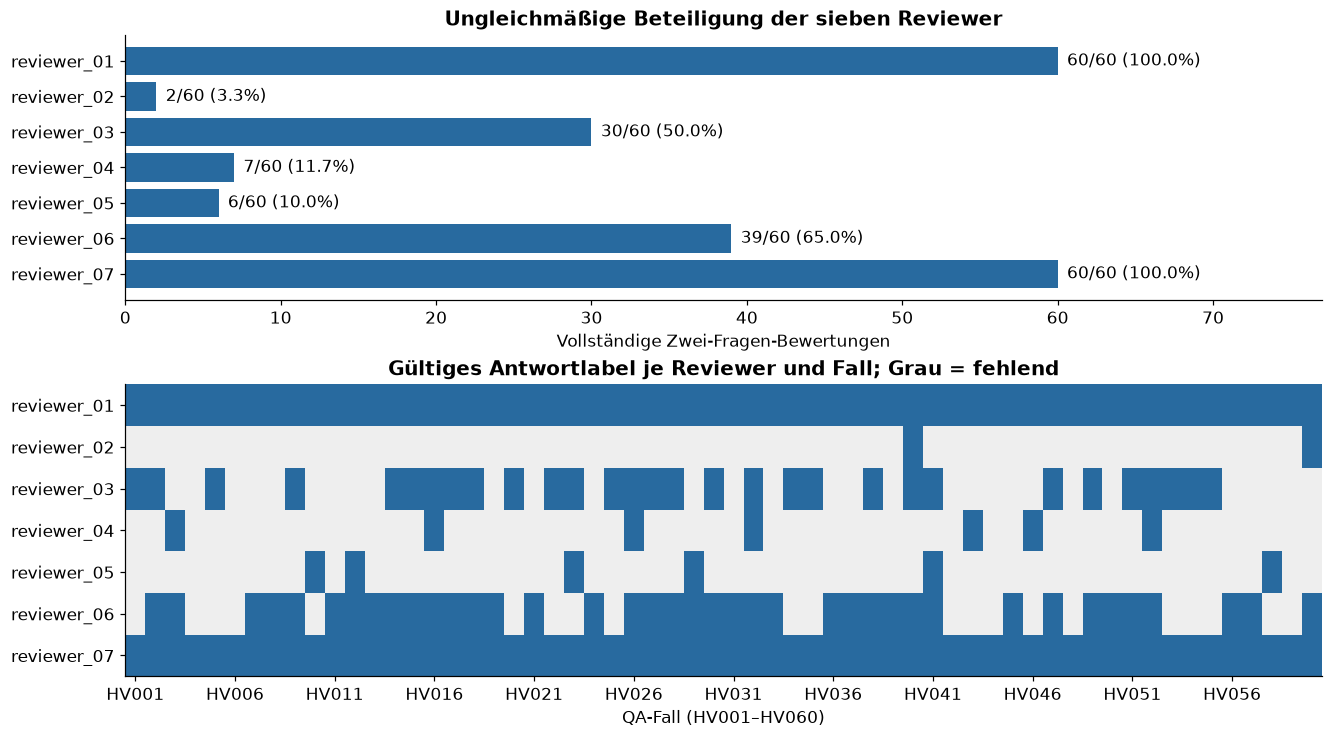

,reviewer_id,erwartete_faelle,vollstaendig,fragenurteile,antworturteile,anteil_vollstaendig
0,reviewer_01,60,60,60,60,1.000
1,reviewer_02,60,2,2,2,0.033
2,reviewer_03,60,30,30,30,0.500
3,reviewer_04,60,7,7,7,0.117
4,reviewer_05,60,6,6,6,0.100
5,reviewer_06,60,39,39,39,0.650
6,reviewer_07,60,60,60,60,1.000


,Anzahl Fälle
Gültige Stimmen pro Fall,
2,6
3,30
4,18
5,6


**Befund:** 204/420 vollständige Bewertungen (48,6 %); pro Fall 2–5 Antwortstimmen. Ausfälle sind anhand der Daten nicht als zufällig nachgewiesen.

In [5]:
completion = annotations.groupby("reviewer_id").agg(
    erwartete_faelle=("review_id", "size"), vollstaendig=("complete", "sum"),
    fragenurteile=("question_quality", "count"), antworturteile=("human_answer_label", "count")).reset_index()
completion["anteil_vollstaendig"] = completion.vollstaendig / completion.erwartete_faelle
assert completion.vollstaendig.tolist() == [60, 2, 30, 7, 6, 39, 60]
votes = annotations.pivot(index="reviewer_id", columns="review_id", values="human_answer_label").reindex(columns=key.review_id)
coverage = votes.notna().astype(int)
fig, (ax, heat) = plt.subplots(2, 1, figsize=(12, 6.6), height_ratios=[1, 1.1], layout="constrained")
ax.barh(completion.reviewer_id, completion.vollstaendig, color="#286a9f")
for i, row in completion.iterrows():
    ax.text(row.vollstaendig + .6, i, f"{row.vollstaendig}/60 ({row.anteil_vollstaendig:.1%})", va="center")
ax.set(xlim=(0, 77), xlabel="Vollständige Zwei-Fragen-Bewertungen", title="Ungleichmäßige Beteiligung der sieben Reviewer")
ax.invert_yaxis()
heat.imshow(coverage, cmap=ListedColormap(["#eeeeee", "#286a9f"]), aspect="auto", vmin=0, vmax=1)
heat.set(yticks=range(7), yticklabels=coverage.index, xticks=range(0, 60, 5),
         xticklabels=coverage.columns[::5], xlabel="QA-Fall (HV001–HV060)", title="Gültiges Antwortlabel je Reviewer und Fall; Grau = fehlend")
savefig(fig, "01_beteiligung_und_missingness")
display(completion.round(3))
export(completion, "reviewer_vollstaendigkeit")
valid_answer = annotations[annotations.human_answer_label.notna()]
valid_question = annotations[annotations.question_quality.notna()]
per_item_votes = valid_answer.groupby("review_id").size()
display(per_item_votes.value_counts().sort_index().rename_axis("Gültige Stimmen pro Fall").rename("Anzahl Fälle").to_frame())
display(Markdown(f"**Befund:** {annotations.complete.sum()}/{len(annotations)} vollständige Bewertungen ({pct(annotations.complete.mean())}); "
                 f"pro Fall {per_item_votes.min()}–{per_item_votes.max()} Antwortstimmen. Ausfälle sind anhand der Daten nicht als zufällig nachgewiesen."))

## 4. Fragenqualität: Einzelurteile und Fallaggregation

Der historische Bericht nennt alle 60 Fragen im Konsens `good`. Das schließt zwei alphabetisch entschiedene Gleichstände ein. Die eindeutige Aggregation, die Einzelurteile und die Zahl einzigartiger Fragen werden deshalb separat ausgewiesen. Wiederholte Fragen über mehrere Zusammenfassungen erzeugen zusätzliche Bewertungen derselben Frage.

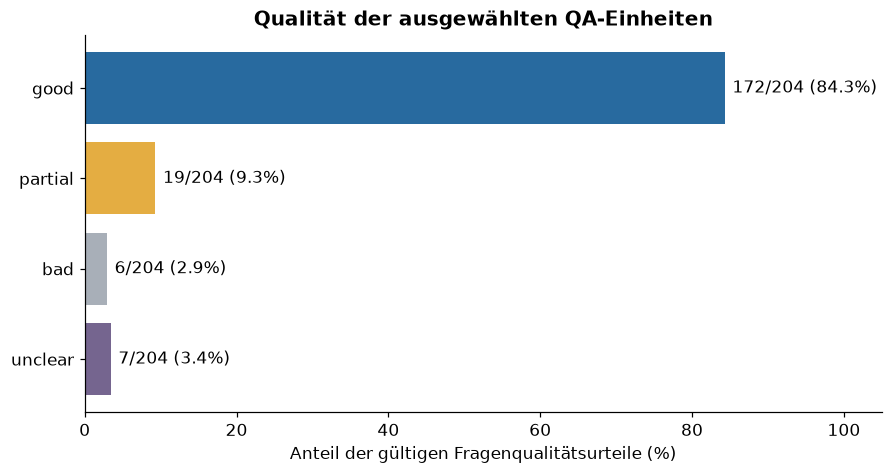

,Label,Urteile,Anteil
0,good,172,0.8431
1,partial,19,0.0931
2,bad,6,0.0294
3,unclear,7,0.0343


**Befund:** 172/204 Urteile sind `good`, 191/204 `good` oder `partial`. Alle 60 historischen Konsenslabels lauten `good`; 2 davon sind Ties. 58/58 eindeutige Fallkonsenslabels sind `good`. Die 60 Einheiten enthalten 25 einzigartige Fragen.

In [6]:
def consensus_table(frame, field):
    records = []
    for review_id, group in frame.groupby("review_id", sort=True):
        labels = group[field].dropna().tolist()
        counts = Counter(labels)
        if not counts:
            records.append({"review_id": review_id, "label": pd.NA, "tie": False, "votes": 0,
                            "max_votes": 0, "strict_majority": False, "unanimous": False})
            continue
        max_votes = max(counts.values())
        winners = sorted(k for k, v in counts.items() if v == max_votes)
        records.append({"review_id": review_id, "label": winners[0], "tie": len(winners) > 1,
                        "votes": len(labels), "max_votes": max_votes,
                        "strict_majority": max_votes > len(labels) / 2,
                        "unanimous": len(counts) == 1})
    return pd.DataFrame(records)
answer_consensus = consensus_table(annotations, "human_answer_label")
question_consensus = consensus_table(annotations, "question_quality")
archived = read("qa/analysis/majority_by_item.csv")
for rebuilt, label_column, tie_column in [(answer_consensus, "majority_answer_label", "answer_label_tie"),
                                          (question_consensus, "majority_question_quality", "question_quality_tie")]:
    aligned = rebuilt.merge(archived[["review_id", label_column, tie_column]], on="review_id", validate="one_to_one")
    assert aligned.label.eq(aligned[label_column]).all()
    assert aligned.tie.eq(bool_col(aligned[tie_column])).all()
items = key.merge(answer_consensus.rename(columns={"label": "human_label"}), on="review_id", validate="one_to_one")
items = items.merge(question_consensus[["review_id", "label", "tie"]].rename(
    columns={"label": "human_question_quality", "tie": "question_tie"}), on="review_id", validate="one_to_one")
items["legacy_eligible"] = items.human_label.isin(LABELS)
items["strict_eligible"] = items.legacy_eligible & ~items.tie
assert items.legacy_eligible.sum() == 58 and items.strict_eligible.sum() == 52
assert items.tie.sum() == 6 and items.question_tie.sum() == 2
qcounts = valid_question.question_quality.value_counts().reindex(QUESTION_LABELS, fill_value=0)
assert qcounts.tolist() == [172, 19, 6, 7]
quality = qcounts.rename_axis("Label").rename("Urteile").reset_index()
quality["Anteil"] = quality.Urteile / len(valid_question)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
bars = ax.barh(quality.Label, quality.Anteil * 100, color=["#286a9f", "#e4ad42", "#a8afb8", "#75658f"])
for bar, row in zip(bars, quality.itertuples()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, f"{row.Urteile}/204 ({row.Anteil:.1%})", va="center")
ax.set(xlim=(0, 105), xlabel="Anteil der gültigen Fragenqualitätsurteile (%)", title="Qualität der ausgewählten QA-Einheiten")
ax.invert_yaxis()
savefig(fig, "02_fragenqualitaet")
display(quality.round(4))
display(Markdown(f"**Befund:** 172/204 Urteile sind `good`, 191/204 `good` oder `partial`. "
                 f"Alle 60 historischen Konsenslabels lauten `good`; {question_consensus.tie.sum()} davon sind Ties. "
                 "58/58 eindeutige Fallkonsenslabels sind `good`. Die 60 Einheiten enthalten 25 einzigartige Fragen."))
export(quality, "fragenqualitaet")
export(question_consensus, "fragenqualitaet_konsens")

## 5. Reliabilität der menschlichen Bewertungen

Die historische rohe Übereinstimmung zählt alle gültigen Reviewerpaare innerhalb der Fälle; Fälle mit mehr Stimmen erhalten mehr Paargewicht. Ergänzend wird der Mittelwert der fallweisen Paarübereinstimmung ausgewiesen.

**Neu berechnet:** nominales Krippendorff-Alpha mit variabler Stimmenzahl. Für jeden Fall mit $m_u\geq2$ wird die Koinzidenzmatrix mit $o_{ck,u}=n_{uc}(n_{uk}-\mathbf{1}_{c=k})/(m_u-1)$ gebildet. Mit den daraus abgeleiteten Randsummen gilt $\alpha=1-D_o/D_e$. Missingness wird nicht durch Auffüllen auf sieben Stimmen beseitigt. `unclear` bleibt primär eine nominale Kategorie; sein Ausschluss ist eine Sensitivitätsrechnung.

Die überwiegende Verwendung von `good` kann hohe rohe Übereinstimmung bei gleichzeitig niedrigem zufallskorrigiertem Alpha erzeugen. Ein ordnungsgemäß berechnetes Alpha ersetzt zudem keine Untersuchung möglicher Beeinflussung durch sichtbare Modellantworten. Definition: [Krippendorff, Computing Alpha-Reliability](https://www.asc.upenn.edu/sites/default/files/2021-03/Computing%20Krippendorff%27s%20Alpha-Reliability.pdf).

In [7]:
def nominal_alpha(frame, field, allowed):
    coincidence = np.zeros((len(allowed), len(allowed)), dtype=float)
    usable_units = 0
    for _, group in frame.groupby("review_id"):
        values = group.loc[group[field].isin(allowed), field]
        m = len(values)
        if m < 2:
            continue
        count = values.value_counts().reindex(allowed, fill_value=0).to_numpy(dtype=float)
        coincidence += (np.outer(count, count) - np.diag(count)) / (m - 1)
        usable_units += 1
    n = coincidence.sum()
    if n < 2:
        return np.nan, usable_units
    marginal = coincidence.sum(axis=0)
    observed = (n - np.trace(coincidence)) / n
    expected = (n*n - np.sum(marginal*marginal)) / (n*(n-1))
    return (1-observed/expected if expected else np.nan), usable_units

# Verifikation anhand des nominalen Beispiels mit zwei Beobachtern in Krippendorffs Originaltext.
example = pd.DataFrame({"review_id": list(range(12))*2,
                       "x": list("aabb dcccedda".replace(" ", "")) + list("babbbccceddd")})
example_alpha, _ = nominal_alpha(example, "x", list("abcde"))
assert np.isclose(example_alpha, 0.6919642857142857), example_alpha

reliability_rows = []
for field, allowed in [("question_quality", QUESTION_LABELS), ("human_answer_label", ANSWER_LABELS)]:
    matches = total = 0
    unit_agreement = []
    for _, group in annotations.groupby("review_id"):
        pairs = list(combinations(group[field].dropna(), 2))
        if pairs:
            unit_matches = sum(a == b for a, b in pairs)
            matches += unit_matches; total += len(pairs)
            unit_agreement.append(unit_matches / len(pairs))
    alpha, usable = nominal_alpha(annotations, field, allowed)
    reliability_rows.append({"Dimension": field, "Übereinstimmende Paare": matches, "Gültige Paare": total,
                             "Rohe Paarübereinstimmung": matches/total,
                             "Fallmittel der Paarübereinstimmung": np.mean(unit_agreement),
                             "Nominales Alpha": alpha, "Fälle für Alpha": usable})
reliability = pd.DataFrame(reliability_rows)
assert reliability["Übereinstimmende Paare"].tolist() == [184, 149]
assert reliability["Gültige Paare"].tolist() == [264, 264]
answer_alpha, _ = nominal_alpha(annotations, "human_answer_label", ANSWER_LABELS)
answer_alpha_three, alpha_three_n = nominal_alpha(annotations, "human_answer_label", LABELS)
display(reliability.round(4))
display(Markdown(f"**Neu berechnet:** Antwortlabels: nominales Alpha = {answer_alpha:.3f} mit `unclear`; "
                 f"ohne `unclear` = {answer_alpha_three:.3f} ({alpha_three_n} auswertbare Fälle). "
                 "Die Fallaggregation erzeugt eine verwendbare Referenz, aber keine fehlerfreie Ground Truth."))
export(reliability, "reliabilitaet")

,Dimension,Übereinstimmende Paare,Gültige Paare,Rohe Paarübereinstimmung,Fallmittel der Paarübereinstimmung,Nominales Alpha,Fälle für Alpha
0,question_quality,184,264,0.6970,0.7267,-0.0337,60
1,human_answer_label,149,264,0.5644,0.5578,0.2967,60


**Neu berechnet:** Antwortlabels: nominales Alpha = 0.297 mit `unclear`; ohne `unclear` = 0.424 (59 auswertbare Fälle). Die Fallaggregation erzeugt eine verwendbare Referenz, aber keine fehlerfreie Ground Truth.

### 5.1 Paarweises Kappa und Konsensstärke

Ungewichtetes Kappa wird nur auf tatsächlich gemeinsam bewerteten Fällen berechnet. Der Nenner steht in jeder Zelle; insbesondere Vergleiche mit zwei oder sechs gemeinsamen Fällen sind instabil. Die Diagonale wird ausgeblendet.

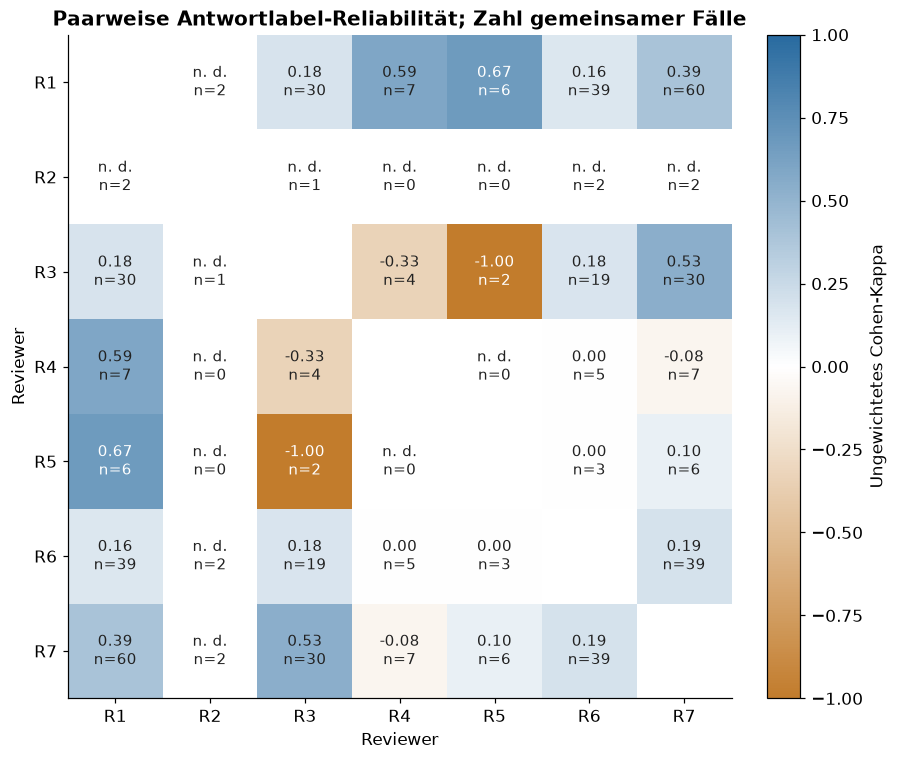

,votes,max_votes,tie,strict_majority,Fälle
0,2,1,True,False,2
1,2,2,False,True,4
2,3,1,True,False,3
3,3,2,False,True,16
4,3,3,False,True,11
5,4,2,False,False,6
6,4,2,True,False,1
7,4,3,False,True,7
8,4,4,False,True,4
9,5,3,False,True,2


,review_id,article_id,human_label,votes,max_votes
6,HV007,1,lost,3,1
10,HV011,2,lost,3,1
22,HV023,3,lost,4,2
34,HV035,4,lost,3,1
41,HV042,5,retained,2,1
43,HV044,5,lost,2,1


In [8]:
reviewers = sorted(annotations.reviewer_id.unique())
pair_rows = []
kappas = np.full((7,7), np.nan)
overlaps = np.zeros((7,7), dtype=int)
for i,j in combinations(range(7), 2):
    common = votes.loc[[reviewers[i], reviewers[j]]].T.dropna()
    n = len(common)
    a,b = common.iloc[:,0], common.iloc[:,1]
    combined = pd.concat([a,b])
    kappa = cohen_kappa_score(a,b) if n and combined.nunique() > 1 else np.nan
    kappas[i,j] = kappas[j,i] = kappa
    overlaps[i,j] = overlaps[j,i] = n
    pair_rows.append({"Reviewer A":reviewers[i],"Reviewer B":reviewers[j],"Gemeinsame Fälle":n,
                      "Rohe Übereinstimmung":a.eq(b).mean() if n else np.nan,"Cohen-Kappa (nominal)":kappa})
fig, ax = plt.subplots(figsize=(8,6.8), layout="constrained")
kappa_cmap = LinearSegmentedColormap.from_list("kappa", ["#c27c2c", "#ffffff", "#286a9f"])
im = ax.imshow(np.ma.masked_invalid(kappas), cmap=kappa_cmap, vmin=-1, vmax=1)
for i in range(7):
    for j in range(7):
        if i != j:
            value = kappas[i,j]
            ax.text(j,i,(f"{value:.2f}" if np.isfinite(value) else "n. d.")+f"\nn={overlaps[i,j]}",
                    ha="center",va="center",color="white" if abs(value) > .6 else "#222222",fontsize=10)
ax.set(xticks=range(7),yticks=range(7),xticklabels=[f"R{i+1}" for i in range(7)],yticklabels=[f"R{i+1}" for i in range(7)],
       xlabel="Reviewer",ylabel="Reviewer",title="Paarweise Antwortlabel-Reliabilität; Zahl gemeinsamer Fälle")
fig.colorbar(im,ax=ax,label="Ungewichtetes Cohen-Kappa")
savefig(fig,"03_reviewer_kappa")
pair_metrics = pd.DataFrame(pair_rows)
export(pair_metrics,"reviewer_paarvergleich")
strength = items.groupby(["votes","max_votes","tie","strict_majority"]).size().rename("Fälle").reset_index()
display(strength)
display(items.loc[items.tie,["review_id","article_id","human_label","votes","max_votes"]])
export(items,"konsens_je_fall")

## 6. Ursprünglicher Scorer: Vergleichsebenen und Fehlerstruktur

Einzelurteil-Accuracy gewichtet Personen mit vielen Rückgaben stärker. Fallkonsens-Accuracy verwendet einen aggregierten Vergleich pro Fall. Der primäre Vergleich schließt `unclear` und nicht eindeutig auflösbare Ties aus. Macro-F1 gewichtet die drei Klassen gleich; eine dominante Klasse wird zusätzlich als deskriptive Vergleichsregel ausgewiesen.

In [9]:
comparable_rows = annotations[annotations.human_answer_label.isin(LABELS)].copy()
row_matches = comparable_rows.model_label.eq(comparable_rows.human_answer_label).sum()
assert len(comparable_rows) == 182 and row_matches == 106
def metric_row(frame, prediction, name):
    y = frame.human_label
    p = frame[prediction]
    if not len(frame):
        return {"Auswertung":name,"Fälle":0,"Übereinstimmungen":0,"Accuracy":np.nan,"Kappa":np.nan,"Macro-F1":np.nan}
    return {"Auswertung":name,"Fälle":len(frame),"Übereinstimmungen":int(y.eq(p).sum()),
            "Accuracy":accuracy_score(y,p),"Kappa":cohen_kappa_score(y,p,labels=LABELS),
            "Macro-F1":f1_score(y,p,labels=LABELS,average="macro",zero_division=0)}
baseline = pd.DataFrame([metric_row(items[items.legacy_eligible],"model_label","Historisch: unclear ausgeschlossen, Ties alphabetisch"),
                         metric_row(items[items.strict_eligible],"model_label","Primär: eindeutiges Drei-Klassen-Label")])
display(baseline.round(4))
assert baseline["Übereinstimmungen"].tolist() == [33,32]
strict = items[items.strict_eligible].copy()
majority_class = strict.human_label.mode().iloc[0]
majority_baseline = strict.human_label.eq(majority_class).mean()
display(Markdown(f"**Befund:** Einzelurteile: {row_matches}/182 = {pct(row_matches/182)}. "
                 f"Eindeutige Fälle: 32/52 = {pct(32/52)}. Die konstante Regel `{majority_class}` erreicht hier "
                 f"{pct(majority_baseline)}; Accuracy allein beschreibt die Klassenfehler deshalb unzureichend."))
export(baseline,"urspruenglicher_scorer_kennzahlen")

,Auswertung,Fälle,Übereinstimmungen,Accuracy,Kappa,Macro-F1
0,"Historisch: unclear ausgeschlossen, Ties alphabetisch",58,33,0.5690,0.3521,0.4709
1,Primär: eindeutiges Drei-Klassen-Label,52,32,0.6154,0.4174,0.5077


**Befund:** Einzelurteile: 106/182 = 58,2 %. Eindeutige Fälle: 32/52 = 61,5 %. Die konstante Regel `retained` erreicht hier 57,7 %; Accuracy allein beschreibt die Klassenfehler deshalb unzureichend.

## 7. Scorer-Kalibrierung auf unveränderten Modellantworten

Hier wird der Einfluss der **Bewertungsregel isoliert**: Fragen, Zusammenfassungen und Antworten bleiben gleich. Der vollständige aktuelle Scorer sowie sein unveränderter Funktionsauszug liegen als Snapshot bei. Das Ausgangslabel wird aus dem ursprünglichen Schlüssel übernommen.

Die erste Kalibrierung wird zusätzlich **nach der dokumentierten Regel rekonstruiert**: Dekaden-/US-Normalisierung und begrenzter Kurzantwort-Fallback (Referenz ≤10 Tokens, Antwort-/Referenzlänge ≤4, F1 ≥0,43). Sie ist kein behaupteter historischer Git-Snapshot. Die zweite dokumentierte Kalibrierung normalisiert u. a. Brüche, Zahlenvergleiche, Artikel und begrenzte Morphologie. Der Auszug des aktuellen Scorers reproduziert die dokumentierten 42/58.

Die erlaubte bidirektionale Zeichenketten-Containment-Prüfung bleibt ein praktischer Heuristikfehler: Sie prüft keine vollständige semantische Äquivalenz. Ein korrektes Zahlenformat genügt nicht, wenn Qualifikatoren, Vergleichsrichtung oder Umfang fehlen.

,Auswertung,Fälle,Übereinstimmungen,Accuracy,Kappa,Macro-F1,Vergleichsset
0,Ursprünglich,58,33,0.5690,0.3521,0.4709,Historisch (n=58)
1,Erste Kalibrierung (rekonstruiert),58,37,0.6379,0.4271,0.5045,Historisch (n=58)
2,Generalisierte Kalibrierung (Snapshot),58,42,0.7241,0.5260,0.5354,Historisch (n=58)
3,Ursprünglich,52,32,0.6154,0.4174,0.5077,Eindeutig (n=52)
4,Erste Kalibrierung (rekonstruiert),52,36,0.6923,0.5039,0.5421,Eindeutig (n=52)
5,Generalisierte Kalibrierung (Snapshot),52,41,0.7885,0.6291,0.5783,Eindeutig (n=52)


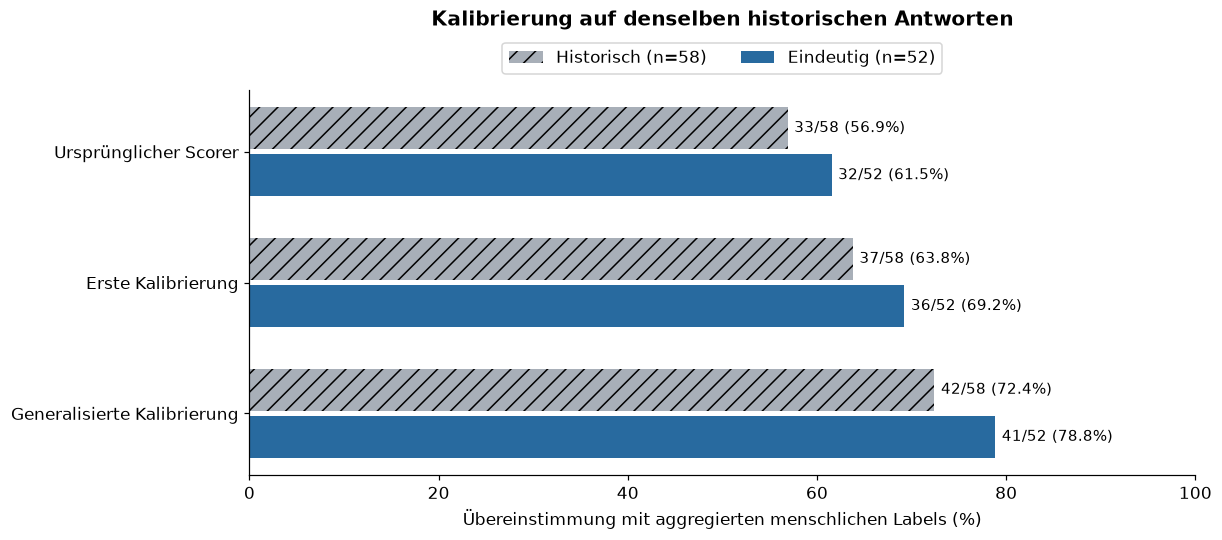

**Interpretation:** 9 zusätzliche Übereinstimmungen auf 52 eindeutigen Fällen (+17,3 Prozentpunkte). Die Verbesserung ist deskriptiv und innerhalb der Kalibrierungsstichprobe gemessen. Einzelurteile steigen von 106/182 auf 128/182 (58,2 % → 70,3 %); diese Zeilen sind nicht unabhängig.

In [10]:
from faktenretention import scoring as scorer
def original_retained(reference, answer):
    if answer.upper() == "NOT_FOUND":
        return False
    r,a = scorer.normalize(reference),scorer.normalize(answer)
    return bool(r and (r in a or a in r)) or scorer.token_f1(reference,answer) >= .50
def first_patch_canonical(text):
    text = scorer.normalize(text)
    for source,target in [("u s a","united states"),("u s","united states"),("usa","united states"),("us","united states")]:
        text = re.sub(rf"\b{source}\b",target,text)
    decades = {"one":10,"two":20,"three":30,"four":40,"five":50,"six":60,"seven":70,"eight":80,"nine":90,"ten":100}
    for word,years in decades.items():
        text = re.sub(rf"\bover {word} decades?\b",f"more than {years} years",text)
        text = re.sub(rf"\b{word} decades?\b",f"{years} years",text)
    return text
def first_patch_retained(reference,answer):
    if original_retained(reference,answer):
        return True
    if answer.upper() == "NOT_FOUND":
        return False
    r,a = first_patch_canonical(reference),first_patch_canonical(answer)
    if r and (r in a or a in r):
        return True
    return bool(0 < len(r.split()) <= 10 and len(a.split()) / len(r.split()) <= 4 and scorer.token_f1(r,a) >= .43)
def classify(reference, answer, retained_function):
    return "lost" if answer.upper() == "NOT_FOUND" else "retained" if retained_function(reference,answer) else "unsupported"
items["reconstructed_original"] = [classify(r,a,original_retained) for r,a in zip(items.reference_answer,items.model_answer)]
assert items.reconstructed_original.eq(items.model_label).all()
items["first_patch"] = [classify(r,a,first_patch_retained) for r,a in zip(items.reference_answer,items.model_answer)]
items["calibrated"] = [classify(r,a,scorer.retained) for r,a in zip(items.reference_answer,items.model_answer)]
versions = [("model_label","Ursprünglich"),("first_patch","Erste Kalibrierung (rekonstruiert)"),("calibrated","Generalisierte Kalibrierung (Snapshot)")]
calibration_rows=[]
for mask,name in [(items.legacy_eligible,"Historisch (n=58)"),(items.strict_eligible,"Eindeutig (n=52)")]:
    for column,title in versions:
        row=metric_row(items[mask],column,title);row["Vergleichsset"]=name;calibration_rows.append(row)
calibration=pd.DataFrame(calibration_rows)
assert calibration[calibration.Vergleichsset.eq("Historisch (n=58)")]["Übereinstimmungen"].tolist() == [33,37,42]
assert calibration[calibration.Vergleichsset.eq("Eindeutig (n=52)")]["Übereinstimmungen"].tolist() == [32,36,41]
calibrated_rows = comparable_rows.merge(items[["review_id","calibrated"]],on="review_id",validate="many_to_one")
assert calibrated_rows.calibrated.eq(calibrated_rows.human_answer_label).sum() == 128
display(calibration.round(4))
export(calibration,"scorer_kalibrierung")
fig,ax=plt.subplots(figsize=(11,4.8),layout="constrained")
y=np.arange(3)
for offset,set_name,color,hatch in [(-.18,"Historisch (n=58)","#a8afb8","//"),(.18,"Eindeutig (n=52)","#286a9f",None)]:
    group=calibration[calibration.Vergleichsset.eq(set_name)]
    bars=ax.barh(y+offset,group.Accuracy*100,height=.32,color=color,hatch=hatch,label=set_name)
    for bar,row in zip(bars,group.itertuples()):
        ax.text(bar.get_width()+.7,bar.get_y()+bar.get_height()/2,f"{row.Übereinstimmungen}/{row.Fälle} ({row.Accuracy:.1%})",va="center",fontsize=10)
ax.set(yticks=y,yticklabels=["Ursprünglicher Scorer","Erste Kalibrierung","Generalisierte Kalibrierung"],xlim=(0,100),
       xlabel="Übereinstimmung mit aggregierten menschlichen Labels (%)",title="Kalibrierung auf denselben historischen Antworten")
ax.invert_yaxis();ax.legend(loc="lower center",bbox_to_anchor=(.5,1.02),ncols=2);ax.set_title(ax.get_title(),pad=42)
savefig(fig,"04_kalibrierung")
display(Markdown("**Interpretation:** 9 zusätzliche Übereinstimmungen auf 52 eindeutigen Fällen (+17,3 Prozentpunkte). "
                 "Die Verbesserung ist deskriptiv und innerhalb der Kalibrierungsstichprobe gemessen. "
                 "Einzelurteile steigen von 106/182 auf 128/182 (58,2 % → 70,3 %); diese Zeilen sind nicht unabhängig."))

### 7.1 Konfusionsmatrizen vor und nach der Kalibrierung

Beide Matrizen verwenden dieselben 52 eindeutigen Fälle. Zeilen sind menschliche Labels, Spalten automatische Labels; Farbe und Prozent beziehen sich auf die jeweilige menschliche Zeile. `unsupported` wird als historische technische Kategorie bezeichnet. Ihre Häufigkeit ist keine verifizierte Halluzinationsrate.

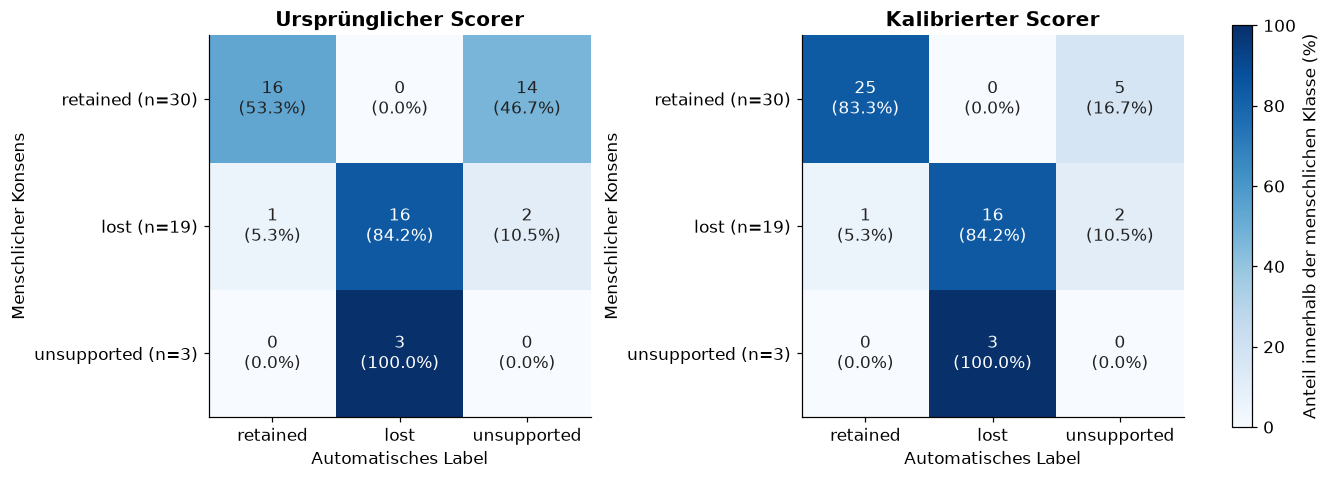

**Original:** 16 automatische `unsupported`-Fälle; davon 0 menschlich ebenfalls `unsupported`. Das ist eine bedingte Stichprobenaussage über das automatische Label, keine Sensitivität für sämtliche Halluzinationen.

**Kalibriert:** 7 automatische `unsupported`-Fälle; davon 0 menschlich ebenfalls `unsupported`. Das ist eine bedingte Stichprobenaussage über das automatische Label, keine Sensitivität für sämtliche Halluzinationen.

,Scorer,Human-Klasse,Human-Fälle,Precision,Recall,F1
0,Original,retained,30,0.9412,0.5333,0.6809
1,Original,lost,19,0.8421,0.8421,0.8421
2,Original,unsupported,3,0.0000,0.0000,0.0000
3,Kalibriert,retained,30,0.9615,0.8333,0.8929
4,Kalibriert,lost,19,0.8421,0.8421,0.8421
5,Kalibriert,unsupported,3,0.0000,0.0000,0.0000


**Messgrenze:** Retained-Recall steigt von 16/30 (53,3 %) auf 25/30 (83,3 %). Die drei menschlichen `unsupported`-Fälle bleiben als `lost` eingestuft (Recall 0/3). Alle sieben verbleibenden automatischen `unsupported`-Fälle haben menschlich `retained` oder `lost`. Es ist damit weder hohe Precision noch hohe Sensitivität für menschliches `unsupported` belegt.

In [11]:
strict=items[items.strict_eligible].copy()
fig,axes=plt.subplots(1,2,figsize=(12,5.3),layout="constrained")
for ax,column,title in zip(axes,["model_label","calibrated"],["Ursprünglicher Scorer","Kalibrierter Scorer"]):
    matrix=confusion_matrix(strict.human_label,strict[column],labels=LABELS)
    shares=matrix/matrix.sum(axis=1,keepdims=True)*100
    im=ax.imshow(shares,cmap="Blues",vmin=0,vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j,i,f"{matrix[i,j]}\n({shares[i,j]:.1f}%)",ha="center",va="center",color="white" if shares[i,j]>55 else "#222222")
    ax.set(xticks=range(3),yticks=range(3),xticklabels=LABELS,
           yticklabels=[f"{label} (n={matrix[i].sum()})" for i,label in enumerate(LABELS)],xlabel="Automatisches Label",ylabel="Menschlicher Konsens",title=title)
    export(pd.DataFrame(matrix,index=LABELS,columns=LABELS).reset_index(names="Human"),f"konfusion_{column}")
fig.colorbar(im,ax=list(axes),shrink=.7,label="Anteil innerhalb der menschlichen Klasse (%)")
savefig(fig,"05_konfusion_vor_nach")
for column,title in [("model_label","Original"),("calibrated","Kalibriert")]:
    group=strict[strict[column].eq("unsupported")]
    display(Markdown(f"**{title}:** {len(group)} automatische `unsupported`-Fälle; "
                     f"davon {group.human_label.eq('unsupported').sum()} menschlich ebenfalls `unsupported`. "
                     "Das ist eine bedingte Stichprobenaussage über das automatische Label, keine Sensitivität für sämtliche Halluzinationen."))
class_rows=[]
for column,title in [("model_label","Original"),("calibrated","Kalibriert")]:
    precision,recall,f1,support=precision_recall_fscore_support(strict.human_label,strict[column],labels=LABELS,zero_division=0)
    for label,p,r,f,n in zip(LABELS,precision,recall,f1,support):
        class_rows.append({"Scorer":title,"Human-Klasse":label,"Human-Fälle":n,"Precision":p,"Recall":r,"F1":f})
class_metrics=pd.DataFrame(class_rows)
display(class_metrics.round(4))
export(class_metrics,"klassenmetriken")
display(Markdown("**Messgrenze:** Retained-Recall steigt von 16/30 (53,3 %) auf 25/30 (83,3 %). "
                 "Die drei menschlichen `unsupported`-Fälle bleiben als `lost` eingestuft (Recall 0/3). "
                 "Alle sieben verbleibenden automatischen `unsupported`-Fälle haben menschlich `retained` oder `lost`. "
                 "Es ist damit weder hohe Precision noch hohe Sensitivität für menschliches `unsupported` belegt."))

### 7.2 Welche konkreten Fälle ändern sich?

Die Veränderungstabelle enthält alle zehn Umklassifikationen. Vier betreffen dieselbe Ereignisfrage aus Artikel 1; diese vier Treffer sind keine vier unabhängig identifizierten Fehlerarten. `HV023` zeigt die Grenze der Morphologienormalisierung: `suspension` bewahrt nicht automatisch den Qualifikator `indefinitely`. Der Fall hat zudem einen menschlichen Tie und ist deshalb nicht im primären Set.

In [12]:
changes=items[items.model_label.ne(items.calibrated)].copy()
changes["Korrektur_gegen_historischen_Konsens"]=changes.calibrated.eq(changes.human_label)
display(changes[["review_id","article_id","canonical_fact_id","reference_answer","model_answer","model_label","calibrated","human_label","tie"]])
assert len(changes)==10 and changes.Korrektur_gegen_historischen_Konsens.sum()==9
export(changes,"alle_umklassifikationen")
changed_strict=changes[changes.strict_eligible]
display(Markdown(f"**Befund:** {len(changed_strict)} eindeutige Fälle werden korrigiert; sie verteilen sich auf "
                 f"{changed_strict.canonical_fact_id.nunique()} einzigartige Fakten aus {changed_strict.article_id.nunique()} Artikeln. "
                 "Die zehnte Änderung widerspricht dem alphabetisch ausgewählten Tie-Label und wird nicht als bestätigter Fehler oder Erfolg gezählt."))
case_ids=["HV001","HV002","HV023","HV033","HV041","HV048"]
case_examples=items[items.review_id.isin(case_ids)][["review_id","reference_answer","model_answer","model_label","calibrated","human_label","tie"]]
export(case_examples,"qualitative_fallbeispiele")

,review_id,article_id,canonical_fact_id,reference_answer,model_answer,model_label,calibrated,human_label,tie
0,HV001,1,1_F03,It was the deadliest in more than 20 years,The summary states this was the deadliest tornado event in over two decades and t...,unsupported,retained,retained,False
2,HV003,1,1_F03,It was the deadliest in more than 20 years,The outbreak was the deadliest in over two decades and represented the most sever...,unsupported,retained,retained,False
3,HV004,1,1_F03,It was the deadliest in more than 20 years,The summary states that this event was the deadliest tornado-related casualty cou...,unsupported,retained,retained,False
5,HV006,1,1_F03,It was the deadliest in more than 20 years,The summary states the outbreak was the deadliest in over two decades and caused ...,unsupported,retained,retained,False
9,HV010,1,1_F14,The Federal Emergency Management Agency,"Federal Emergency Management Agency teams were deployed, and Homeland Security Se...",unsupported,retained,retained,False
22,HV023,3,3_F08,He was suspended indefinitely,suspension,unsupported,retained,lost,True
32,HV033,4,4_F16,By a third,one-third,unsupported,retained,retained,False
40,HV041,5,5_F06,as a genocide,The United States characterizes the Darfur crisis as genocide.,unsupported,retained,retained,False
45,HV046,5,5_F06,as a genocide,"The United States characterizes the Darfur crisis as genocide, a stance that cont...",unsupported,retained,retained,False
47,HV048,5,5_F18,More than 115,over 115,unsupported,retained,retained,False


**Befund:** 9 eindeutige Fälle werden korrigiert; sie verteilen sich auf 5 einzigartige Fakten aus 3 Artikeln. Die zehnte Änderung widerspricht dem alphabetisch ausgewählten Tie-Label und wird nicht als bestätigter Fehler oder Erfolg gezählt.

## 8. Fehler nach Methode, Kompressionsstufe und Entitätstyp

Diese Schnitte prüfen, ob der Messfehler systematisch mit experimentellen Bedingungen variiert. Sie sind **keine Rangliste der Zusammenfassungsmethoden**: Die abhängige Größe ist Scorer-Mensch-Übereinstimmung, nicht Retention. Auch ein identischer Scorer kann paraphrasenreiche Methoden anders behandeln. Die gezielte Stichprobe und kleinen Zellen verhindern kausale Schlussfolgerungen.

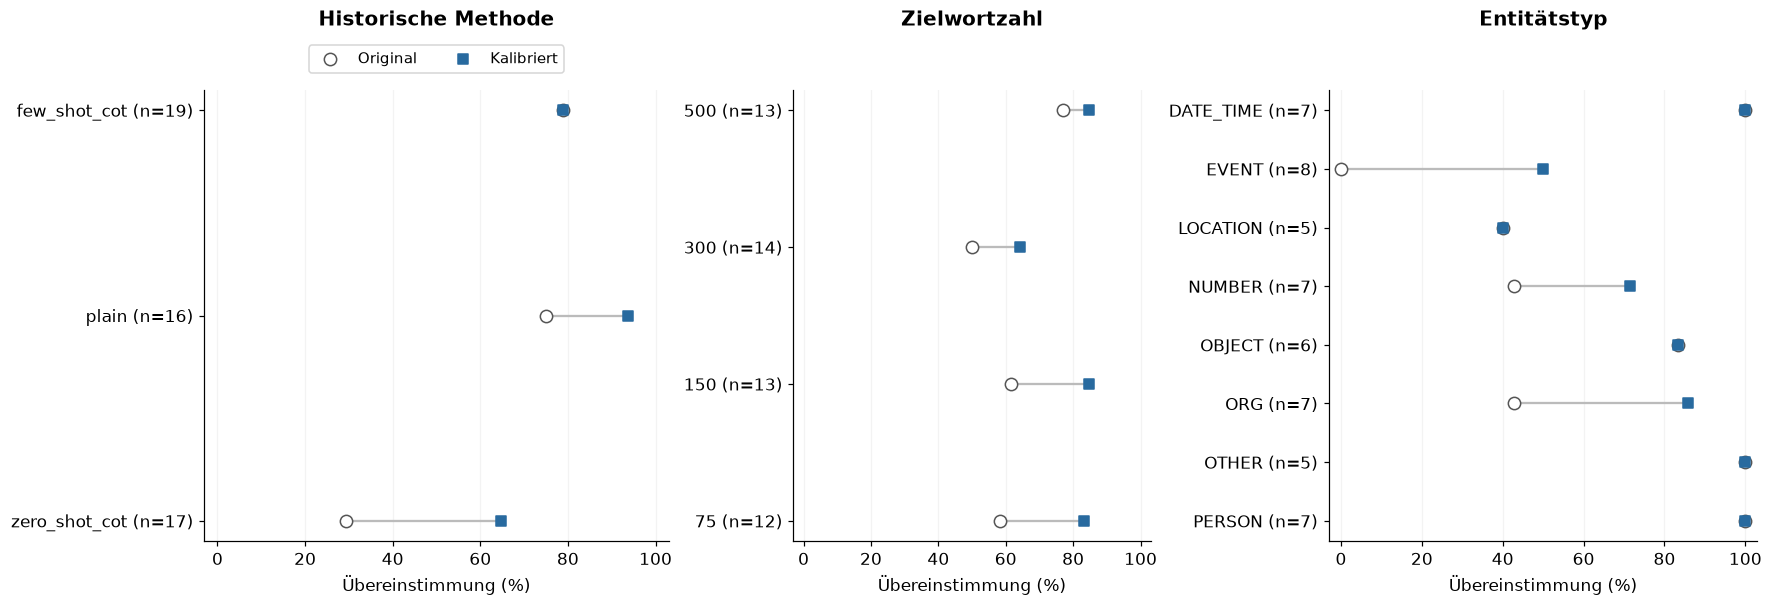

,Dimension,Ausprägung,Fälle,Original korrekt,Kalibriert korrekt,Original Accuracy,Kalibriert Accuracy,Änderung (Prozentpunkte)
0,method,few_shot_cot,19,15,15,0.7895,0.7895,0.0000
1,method,plain,16,12,15,0.7500,0.9375,18.7500
2,method,zero_shot_cot,17,5,11,0.2941,0.6471,35.2941
3,stage_target_words,75,12,7,10,0.5833,0.8333,25.0000
4,stage_target_words,150,13,8,11,0.6154,0.8462,23.0769
5,stage_target_words,300,14,7,9,0.5000,0.6429,14.2857
6,stage_target_words,500,13,10,11,0.7692,0.8462,7.6923
7,entity_type,DATE_TIME,7,7,7,1.0000,1.0000,0.0000
8,entity_type,EVENT,8,0,4,0.0000,0.5000,50.0000
9,entity_type,LOCATION,5,2,2,0.4000,0.4000,0.0000


In [13]:
subgroups=[]
for dimension in ["method","stage_target_words","entity_type","article_id"]:
    for value,group in strict.groupby(dimension):
        before=group.model_label.eq(group.human_label).sum()
        after=group.calibrated.eq(group.human_label).sum()
        subgroups.append({"Dimension":dimension,"Ausprägung":str(value),"Fälle":len(group),"Original korrekt":before,
                          "Kalibriert korrekt":after,"Original Accuracy":before/len(group),"Kalibriert Accuracy":after/len(group),
                          "Änderung (Prozentpunkte)":(after-before)/len(group)*100})
subgroups=pd.DataFrame(subgroups)
fig,axes=plt.subplots(1,3,figsize=(16,5.4),layout="constrained",width_ratios=[1.3,1,1.2])
for ax,dimension,title in zip(axes,["method","stage_target_words","entity_type"],["Historische Methode","Zielwortzahl","Entitätstyp"]):
    group=subgroups[subgroups.Dimension.eq(dimension)].copy()
    if dimension=="stage_target_words":
        group=group.assign(order=group.Ausprägung.astype(int)).sort_values("order",ascending=False)
    y=np.arange(len(group))
    ax.plot(np.stack([group["Original Accuracy"],group["Kalibriert Accuracy"]])*100,np.stack([y,y]),color="#bbbbbb")
    ax.scatter(group["Original Accuracy"]*100,y,facecolors="white",edgecolors="#555555",s=65,label="Original",zorder=3)
    ax.scatter(group["Kalibriert Accuracy"]*100,y,color="#286a9f",marker="s",s=45,label="Kalibriert",zorder=3)
    ax.set(yticks=y,yticklabels=[f"{v} (n={n})" for v,n in zip(group.Ausprägung,group.Fälle)],xlim=(-3,103),xlabel="Übereinstimmung (%)",title=title)
    ax.invert_yaxis();ax.grid(axis="x",alpha=.15)
axes[0].legend(loc="lower center",bbox_to_anchor=(.5,1.02),ncols=2,fontsize=10)
for ax in axes: ax.set_title(ax.get_title(),pad=42)
savefig(fig,"06_subgruppen")
display(subgroups.round(4))
export(subgroups,"subgruppen")

## 9. Sensitivität gegenüber Konsensbildung und Gewichtung

Ein eindeutig häufigstes Label ist nicht zwingend eine absolute Mehrheit. Deshalb werden mehrere vertretbare Analyseentscheidungen transparent verglichen. Die Primäranalyse bleibt unverändert; Sensitivitätssets werden nicht nach dem besten Ergebnis ausgewählt. Das Set mit nur zwei vollständig annotierenden Personen verlangt deren Übereinstimmung und ist eine zusätzliche, selektive Teilmenge.

In [14]:
full_reviewers=completion.loc[completion.vollstaendig.eq(60),"reviewer_id"].tolist()
full_consensus=consensus_table(annotations[annotations.reviewer_id.isin(full_reviewers)],"human_answer_label")
two_complete=items.drop(columns=["human_label","tie","votes","max_votes","strict_majority","unanimous"]).merge(
    full_consensus.rename(columns={"label":"human_label"}),on="review_id",validate="one_to_one")
two_complete=two_complete[two_complete.human_label.isin(LABELS)&~two_complete.tie]
sets={"Historisch: Ties alphabetisch":items[items.legacy_eligible],
      "Primär: Ties + unclear ausgeschlossen":strict,
      "Absolute Mehrheit + kein unclear":items[items.legacy_eligible & items.strict_majority],
      "Zusätzlich eindeutige gute Fragenqualität":strict[strict.human_question_quality.eq("good") & ~strict.question_tie],
      "Nur zwei vollständige Reviewer, deren Übereinstimmung":two_complete}
sensitivity_rows=[]
for name,group in sets.items():
    for column,title in [("model_label","Original"),("calibrated","Kalibriert")]:
        row=metric_row(group,column,name);row["Scorer"]=title;sensitivity_rows.append(row)
sensitivity=pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))
weighting=[]
for column,title in [("model_label","Original"),("calibrated","Kalibriert")]:
    group=strict.assign(correct=strict[column].eq(strict.human_label).astype(float))
    weighting.append({"Scorer":title,"Fallgleich gewichtet":group.correct.mean(),
                      "Artikelgleich gewichtet":group.groupby("article_id").correct.mean().mean(),
                      "Faktgleich gewichtet":group.groupby(["article_id","canonical_fact_id"]).correct.mean().mean()})
weighting=pd.DataFrame(weighting)
display(weighting.round(4))
export(sensitivity,"konsens_sensitivitaet")
export(weighting,"gewichtung_sensitivitaet")

,Auswertung,Fälle,Übereinstimmungen,Accuracy,Kappa,Macro-F1,Scorer
0,Historisch: Ties alphabetisch,58,33,0.5690,0.3521,0.4709,Original
1,Historisch: Ties alphabetisch,58,42,0.7241,0.5260,0.5354,Kalibriert
2,Primär: Ties + unclear ausgeschlossen,52,32,0.6154,0.4174,0.5077,Original
3,Primär: Ties + unclear ausgeschlossen,52,41,0.7885,0.6291,0.5783,Kalibriert
4,Absolute Mehrheit + kein unclear,48,31,0.6458,0.4538,0.5260,Original
5,Absolute Mehrheit + kein unclear,48,40,0.8333,0.6930,0.5971,Kalibriert
6,Zusätzlich eindeutige gute Fragenqualität,50,32,0.6400,0.4448,0.5177,Original
7,Zusätzlich eindeutige gute Fragenqualität,50,40,0.8000,0.6481,0.5826,Kalibriert
8,"Nur zwei vollständige Reviewer, deren Übereinstimmung",36,27,0.7500,0.5883,0.5667,Original
9,"Nur zwei vollständige Reviewer, deren Übereinstimmung",36,33,0.9167,0.8464,0.6381,Kalibriert


,Scorer,Fallgleich gewichtet,Artikelgleich gewichtet,Faktgleich gewichtet
0,Original,0.6154,0.6042,0.5638
1,Kalibriert,0.7885,0.7778,0.7377


### 9.1 Einfluss einzelner Artikel und Reviewer

Beim Weglassen eines Artikels bleiben die menschlichen Labels der übrigen Fälle unverändert. Beim Weglassen eines Reviewers wird der Konsens vollständig neu berechnet, einschließlich neuer Ties. Die resultierenden Nenner können sich ändern; Prozentwerte sind daher immer zusammen mit Fallzahlen zu lesen. Die Spannen messen empirische Stabilität in dieser Stichprobe.

,Typ,Ausgeschlossen,Fälle,Original,Kalibriert,Delta (pp)
0,Artikel,1,43,0.6744,0.7674,9.3023
1,Artikel,2,43,0.5349,0.7442,20.9302
2,Artikel,3,45,0.6000,0.8000,20.0000
3,Artikel,4,43,0.5814,0.7674,18.6047
4,Artikel,5,44,0.7273,0.8636,13.6364
5,Artikel,6,42,0.5714,0.7857,21.4286
6,Reviewer,reviewer_01,41,0.6341,0.8293,19.5122
7,Reviewer,reviewer_02,52,0.6154,0.7885,17.3077
8,Reviewer,reviewer_03,48,0.6250,0.8125,18.7500
9,Reviewer,reviewer_04,50,0.6400,0.8000,16.0000


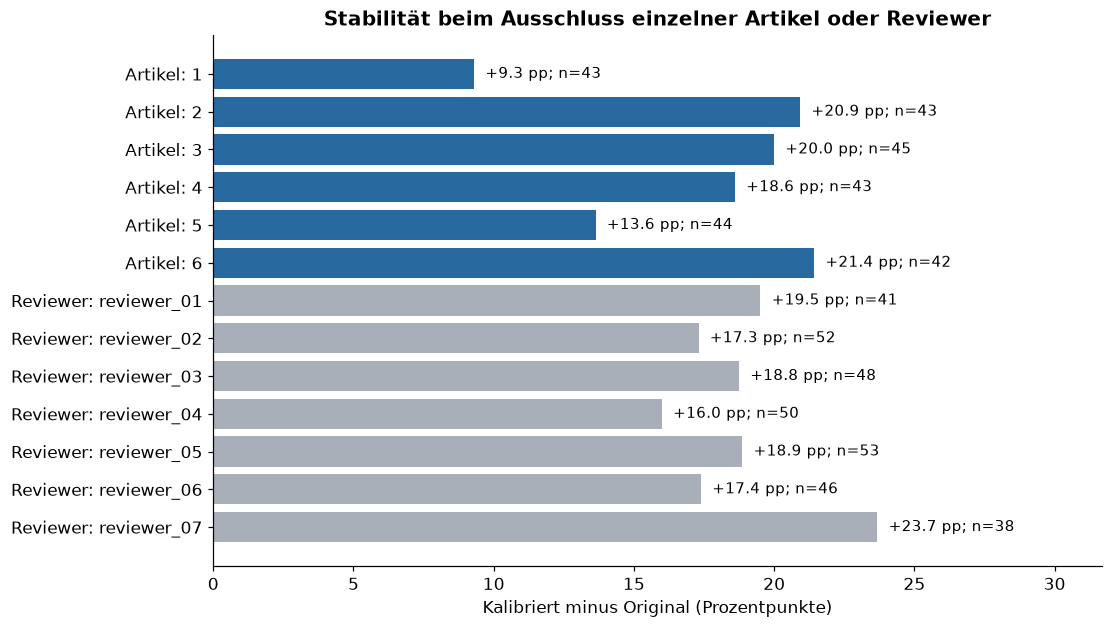

In [15]:
leave_out=[]
for article in sorted(items.article_id.unique()):
    group=strict[strict.article_id.ne(article)]
    before=group.model_label.eq(group.human_label).mean();after=group.calibrated.eq(group.human_label).mean()
    leave_out.append({"Typ":"Artikel","Ausgeschlossen":str(article),"Fälle":len(group),"Original":before,"Kalibriert":after,"Delta (pp)":(after-before)*100})
for reviewer in reviewers:
    rebuilt=consensus_table(annotations[annotations.reviewer_id.ne(reviewer)],"human_answer_label")
    group=items[["review_id","model_label","calibrated"]].merge(rebuilt.rename(columns={"label":"human_label"}),on="review_id",validate="one_to_one")
    group=group[group.human_label.isin(LABELS)&~group.tie]
    before=group.model_label.eq(group.human_label).mean();after=group.calibrated.eq(group.human_label).mean()
    leave_out.append({"Typ":"Reviewer","Ausgeschlossen":reviewer,"Fälle":len(group),"Original":before,"Kalibriert":after,"Delta (pp)":(after-before)*100})
leave_out=pd.DataFrame(leave_out)
display(leave_out.round(4))
export(leave_out,"leave_one_out_stabilitaet")
fig,ax=plt.subplots(figsize=(10,5.6),layout="constrained")
y=np.arange(len(leave_out))
ax.barh(y,leave_out["Delta (pp)"],color=["#286a9f" if t=="Artikel" else "#a8afb8" for t in leave_out.Typ])
for i,row in leave_out.iterrows():
    ax.text(row["Delta (pp)"]+.4,i,f"{row['Delta (pp)']:+.1f} pp; n={row.Fälle}",va="center",fontsize=10)
ax.set(yticks=y,yticklabels=leave_out.Typ+": "+leave_out.Ausgeschlossen,
       xlim=(0,max(leave_out["Delta (pp)"])+8),xlabel="Kalibriert minus Original (Prozentpunkte)",title="Stabilität beim Ausschluss einzelner Artikel oder Reviewer")
ax.invert_yaxis();savefig(fig,"07_leave_one_out")

### 9.2 Reviewer–Modell und Reviewer–andere Reviewer

Je Person werden Modellübereinstimmung und Übereinstimmung mit dem Konsens der **anderen** Personen ausgewiesen. Der Ausschluss des eigenen Urteils vermeidet eine mechanisch erhöhte Konsensübereinstimmung. Die Vergleichssets unterscheiden sich zwischen Personen; diese Tabelle bewertet keine Reviewerkompetenz.

,Reviewer,Modellvergleich n,Original Accuracy,Kalibriert Accuracy,Fremdkonsens n,Übereinstimmung Fremdkonsens
0,reviewer_01,55,0.5091,0.6727,36,0.7778
1,reviewer_02,2,1.0000,1.0000,2,1.0000
2,reviewer_03,27,0.6296,0.7037,21,0.7619
3,reviewer_04,7,0.4286,0.7143,5,0.8000
4,reviewer_05,6,0.3333,0.6667,6,0.6667
5,reviewer_06,29,0.5517,0.6552,22,0.7273
6,reviewer_07,56,0.6786,0.7500,36,0.8333


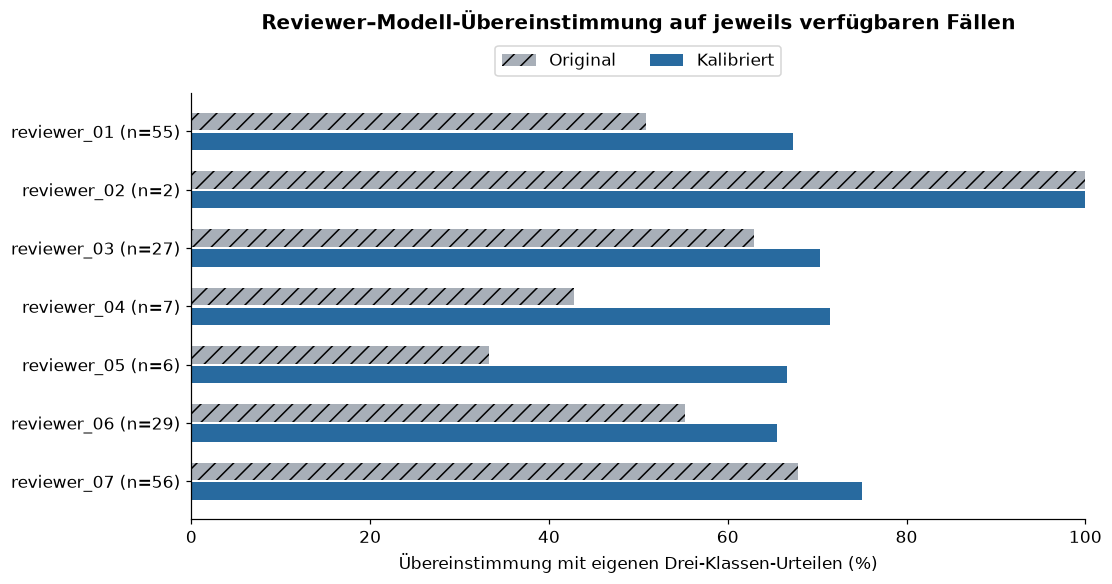

In [16]:
participant_rows=[]
for reviewer in reviewers:
    own=annotations[annotations.reviewer_id.eq(reviewer)&annotations.human_answer_label.isin(LABELS)].merge(
        items[["review_id","calibrated"]],on="review_id",validate="one_to_one")
    other_consensus=consensus_table(annotations[annotations.reviewer_id.ne(reviewer)],"human_answer_label")
    other=own.merge(other_consensus,on="review_id",validate="one_to_one")
    other=other[other.label.isin(LABELS)&~other.tie]
    participant_rows.append({"Reviewer":reviewer,"Modellvergleich n":len(own),
                             "Original Accuracy":own.model_label.eq(own.human_answer_label).mean(),
                             "Kalibriert Accuracy":own.calibrated.eq(own.human_answer_label).mean(),
                             "Fremdkonsens n":len(other),"Übereinstimmung Fremdkonsens":other.label.eq(other.human_answer_label).mean()})
participant_metrics=pd.DataFrame(participant_rows)
display(participant_metrics.round(4))
export(participant_metrics,"reviewer_modell_und_fremdkonsens")
fig,ax=plt.subplots(figsize=(10,5.2),layout="constrained")
y=np.arange(len(participant_metrics))
for offset,column,color,hatch,label in [(-.17,"Original Accuracy","#a8afb8","//","Original"),
                                        (.17,"Kalibriert Accuracy","#286a9f",None,"Kalibriert")]:
    ax.barh(y+offset,participant_metrics[column]*100,height=.30,color=color,hatch=hatch,label=label)
ax.set(yticks=y,yticklabels=[f"{r} (n={n})" for r,n in zip(participant_metrics.Reviewer,participant_metrics["Modellvergleich n"])],
       xlim=(0,100),xlabel="Übereinstimmung mit eigenen Drei-Klassen-Urteilen (%)",title="Reviewer–Modell-Übereinstimmung auf jeweils verfügbaren Fällen")
ax.invert_yaxis();ax.legend(loc="lower center",bbox_to_anchor=(.5,1.02),ncols=2);ax.set_title(ax.get_title(),pad=42)
savefig(fig,"09_reviewer_modell_uebereinstimmung")

## 10. Promptänderung und Scoreränderung getrennt betrachten

Die historischen Prompt-Reruns erzeugten neue Antworten. Ihre archivierten Ausgangslabels werden geprüft; außerdem werden dieselben Antworten mit dem heutigen eingefrorenen Scorer bewertet. So bleiben Antwortänderung und Bewertungsänderung getrennt. Die ursprünglich dokumentierten 30/58 (v1) und 34/58 (v2) werden reproduziert, aber nicht mit der primären 52-Fall-Accuracy vermischt.

Ergänzend liegen drei spätere allgemeine Promptvarianten vor. Auch diese verwenden die bisherigen 60 Fälle und sind **explorative Entwicklung**, kein neuer Testdatensatz. Es werden keine neuen Modelle aufgerufen.

In [17]:
prompt_rows=[]
for name,folder in [("Prompt v1","optimized_answer_prompt"),("Prompt v2","optimized_answer_prompt_v2")]:
    rerun=read(f"qa/analysis/{folder}/optimized_prompt_answers_vs_human_majority.csv")
    assert len(rerun)==60 and rerun.review_id.is_unique and set(rerun.review_id)==set(items.review_id)
    joined=items[["review_id","human_label","legacy_eligible","strict_eligible"]].merge(rerun,on="review_id",validate="one_to_one")
    joined["original_prediction"]=[classify(r,a,original_retained) for r,a in zip(joined.reference_answer,joined.new_answer)]
    assert joined.original_prediction.eq(joined.new_model_label).all()
    joined["calibrated_prediction"]=[classify(r,a,scorer.retained) for r,a in zip(joined.reference_answer,joined.new_answer)]
    historical=joined[joined.legacy_eligible]
    assert historical.original_prediction.eq(historical.human_label).sum()==(30 if name=="Prompt v1" else 34)
    prompt_rows.append({"Prompt":name,"Historisch Originalscorer n":len(historical),
                       "Historisch korrekt":historical.original_prediction.eq(historical.human_label).sum()})
    for column,title in [("original_prediction","Originalscorer"),("calibrated_prediction","Kalibrierter Scorer")]:
        selected=joined[joined.strict_eligible]
        prompt_rows.append({"Prompt":name,"Scorer":title,"Primär n":len(selected),
                           "Primär korrekt":selected[column].eq(selected.human_label).sum(),"Primär Accuracy":selected[column].eq(selected.human_label).mean()})
general=read("qa/analysis/three_general_prompt_test/prompt_test_answers.csv")
assert len(general)==180 and not general[["prompt_variant","review_id"]].duplicated().any()
for name,group in general.groupby("prompt_variant"):
    assert len(group)==60 and set(group.review_id)==set(items.review_id)
    joined=items[["review_id","human_label","strict_eligible"]].merge(group,on="review_id",validate="one_to_one")
    for function,column in [(original_retained,"original_scorer_label"),(scorer.retained,"final_scorer_label")]:
        reconstructed=[classify(r,a,function) for r,a in zip(joined.reference_answer,joined.answer)]
        assert joined[column].eq(reconstructed).all()
    for column,title in [("original_scorer_label","Originalscorer"),("final_scorer_label","Kalibrierter Scorer")]:
        selected=joined[joined.strict_eligible]
        prompt_rows.append({"Prompt":name,"Scorer":title,"Primär n":len(selected),
                           "Primär korrekt":selected[column].eq(selected.human_label).sum(),"Primär Accuracy":selected[column].eq(selected.human_label).mean()})
prompt_comparison=pd.DataFrame(prompt_rows)
display(prompt_comparison)
export(prompt_comparison,"prompt_scorer_vergleich")

,Prompt,Historisch Originalscorer n,Historisch korrekt,Scorer,Primär n,Primär korrekt,Primär Accuracy
0,Prompt v1,58.0,30.0,NaN,NaN,NaN,NaN
1,Prompt v1,NaN,NaN,Originalscorer,52.0,29.0,0.557692
2,Prompt v1,NaN,NaN,Kalibrierter Scorer,52.0,37.0,0.711538
3,Prompt v2,58.0,34.0,NaN,NaN,NaN,NaN
4,Prompt v2,NaN,NaN,Originalscorer,52.0,33.0,0.634615
5,Prompt v2,NaN,NaN,Kalibrierter Scorer,52.0,36.0,0.692308
6,a_minimal_evidence_span,NaN,NaN,Originalscorer,52.0,29.0,0.557692
7,a_minimal_evidence_span,NaN,NaN,Kalibrierter Scorer,52.0,33.0,0.634615
8,b_typed_granularity_decision,NaN,NaN,Originalscorer,52.0,31.0,0.596154
9,b_typed_granularity_decision,NaN,NaN,Kalibrierter Scorer,52.0,37.0,0.711538


## 11. September: Antworterwechsel auf denselben historischen Human-Fällen

Der kontrollierte Benchmark vergleicht GLM und Qwen3.8 auf 2.400 identischen QA-Einheiten aus zehn Artikeln; er wird hier ausschließlich als Kontext zum späteren Antworterwechsel verwendet. Alle 60 Human-Fälle sind darin enthalten. Es wurden keine neuen menschlichen Bewertungen erhoben; zudem beziehen sich die alten Urteile auf das damals sichtbare Antwortmaterial. Der Vergleich mit neuen Qwen-Antworten ist damit eine Übereinstimmung mit historischen Referenzurteilen und keine erneute Bewertung dieser Antworten.

**Nennerkorrektur:** Der archivierte Benchmark schließt Ties aus, zählt aber zwei `unclear`-Konsensfälle als vergleichbar und beide als Nichtübereinstimmung. Deshalb ergeben sich 41/54 und 39/54. Für eine echte Drei-Klassen-Accuracy werden zusätzlich diese beiden Fälle ausgeschlossen: 41/52 und 39/52. Die archivierten Artikel-Bootstrap-Intervalle gehören zum archivierten 54-Fall-Protokoll; sie werden nicht auf das 52-Fall-Protokoll übertragen.

In [18]:
benchmark=read("qa_spaeterer_antworterabgleich/report/human_validation_subset.csv")
assert len(benchmark)==120 and not benchmark[["answerer","review_id"]].duplicated().any()
benchmark=benchmark.merge(items[["review_id","human_label","tie","strict_eligible","article_id","method","stage_target_words","canonical_fact_id","generated_question","reference_answer"]],
                          on="review_id",validate="many_to_one",suffixes=("_benchmark",""))
assert benchmark.human_majority_label.eq(benchmark.human_label).all()
assert bool_col(benchmark.human_label_tie).eq(benchmark.tie).all()
for column in ["article_id","method","canonical_fact_id","reference_answer"]:
    assert benchmark[column+"_benchmark"].eq(benchmark[column]).all(),column
assert benchmark.stage.eq(benchmark.stage_target_words).all()
assert benchmark.question.eq(benchmark.generated_question).all()
benchmark_rows=[]
for answerer,group in benchmark.groupby("answerer"):
    for name,mask in [("Archiv: ohne Ties (inkl. unclear)",bool_col(group.comparable)),("Harmonisiert: ohne Ties und unclear",group.strict_eligible)]:
        selected=group[mask]
        matches=selected.model_label.eq(selected.human_label).sum()
        benchmark_rows.append({"Antworter":answerer,"Vergleichsset":name,"Fälle":len(selected),"Übereinstimmungen":matches,"Accuracy":matches/len(selected)})
benchmark_agreement=pd.DataFrame(benchmark_rows)
assert benchmark_agreement["Übereinstimmungen"].tolist()==[41,41,39,39]
assert benchmark_agreement["Fälle"].tolist()==[54,52,54,52]
display(benchmark_agreement.round(4))
display(benchmark.loc[benchmark.human_label.eq("unclear"),["review_id","answerer","human_label","model_label","comparable","agreement"]])
display(read("qa_spaeterer_antworterabgleich/report/human_agreement_bootstrap.csv"))
export(benchmark_agreement,"spaeterer_antworterabgleich")

,Antworter,Vergleichsset,Fälle,Übereinstimmungen,Accuracy
0,glm,Archiv: ohne Ties (inkl. unclear),54,41,0.7593
1,glm,Harmonisiert: ohne Ties und unclear,52,41,0.7885
2,qwen,Archiv: ohne Ties (inkl. unclear),54,39,0.7222
3,qwen,Harmonisiert: ohne Ties und unclear,52,39,0.7500


,review_id,answerer,human_label,model_label,comparable,agreement
54,HV028,glm,unclear,retained,1,0
55,HV028,qwen,unclear,retained,1,0
58,HV030,glm,unclear,unsupported,1,0
59,HV030,qwen,unclear,unsupported,1,0


,metric,difference_qwen_minus_glm,ci95_low,ci95_high,bootstrap_samples,independent_articles
0,human_majority_agreement,-0.034722,-0.092593,0.043981,10000,6


### 11.1 Kontext des gesamten Antworterbenchmarks

Retention im vollständigen Benchmark ist eine automatische Messgröße und darf nicht mit der Mensch-Modell-Accuracy verwechselt werden. Höhere gemessene Retention allein belegt keine höhere Messvalidität. Die zehn Artikel sind die Cluster für den archivierten gepaarten Bootstrap; für den Human-Subset sind es sechs Artikel. Die Laufzeiten stammen aus verschiedenen Ausführungsdaten und werden hier nicht als kontrollierter Geschwindigkeitsvergleich interpretiert.

,answerer,rows,retention_rate,loss_rate,reference_discordant_rate,literal_false_negative_rate,error_rows
0,glm,2400,0.4000,0.5000,0.1000,0.1695,0
1,qwen,2400,0.4712,0.4325,0.0962,0.0903,0


,metric,difference_qwen_minus_glm,ci95_low,ci95_high,bootstrap_samples,independent_articles
0,retention,0.0712,0.0546,0.0875,10000,10
1,loss,-0.0675,-0.0929,-0.0404,10000,10
2,reference_discordant,-0.0038,-0.0271,0.0179,10000,10
3,token_f1,0.0625,0.0505,0.0748,10000,10
4,literal_false_negative,-0.0869,-0.1333,-0.0424,10000,10


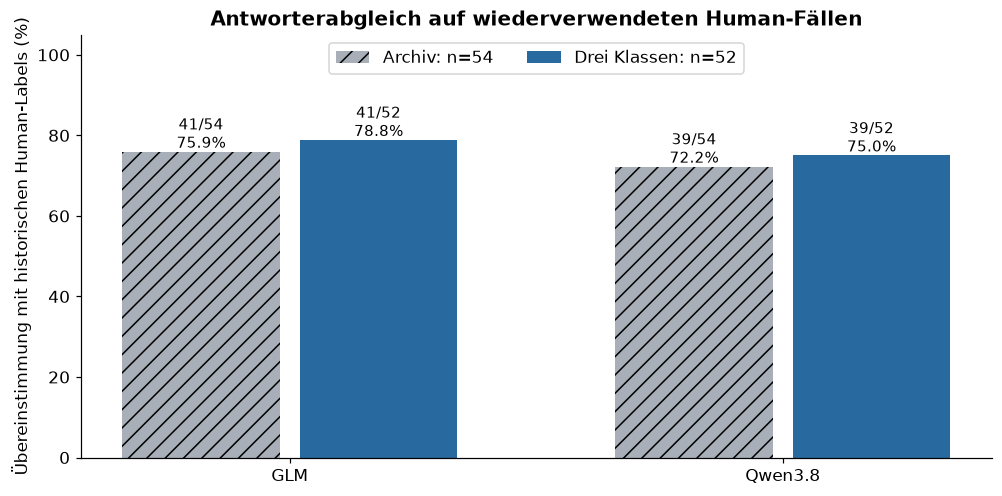

In [19]:
overall=read("qa_spaeterer_antworterabgleich/report/overall.csv")
bootstrap=read("qa_spaeterer_antworterabgleich/report/paired_article_bootstrap.csv")
display(overall[["answerer","rows","retention_rate","loss_rate","reference_discordant_rate","literal_false_negative_rate","error_rows"]].round(4))
display(bootstrap.round(4))
assert overall.rows.eq(2400).all() and overall.error_rows.eq(0).all()
export(overall,"gesamtbenchmark_kontext")
export(bootstrap,"gesamtbenchmark_archivierte_intervalle")
fig,ax=plt.subplots(figsize=(9,4.4),layout="constrained")
x=np.arange(2)
for offset,color,mask,label,hatch in [(-.18,"#a8afb8",benchmark_agreement.Vergleichsset.str.startswith("Archiv"),"Archiv: n=54","//"),
                                     (.18,"#286a9f",benchmark_agreement.Vergleichsset.str.startswith("Harmonisiert"),"Drei Klassen: n=52",None)]:
    group=benchmark_agreement[mask]
    bars=ax.bar(x+offset,group.Accuracy*100,width=.32,color=color,hatch=hatch,label=label)
    for bar,row in zip(bars,group.itertuples()):
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+1,f"{row.Übereinstimmungen}/{row.Fälle}\n{row.Accuracy:.1%}",ha="center",fontsize=10)
ax.set(xticks=x,xticklabels=["GLM","Qwen3.8"],ylim=(0,105),ylabel="Übereinstimmung mit historischen Human-Labels (%)",
       title="Antworterabgleich auf wiederverwendeten Human-Fällen")
ax.legend(loc="upper center",ncols=2)
savefig(fig,"08_spaeterer_antworterabgleich")

## 12. Übertragbarkeit auf das Hauptexperiment

Das finale eingefrorene Protokoll ist die maßgebliche Quelle für die tatsächlich verwendete Pipeline. Es nennt `thesis-gemma:v1` als Faktgenerator (24 Kandidaten, 20 geeignete Fakten), `thesis-qwen38-qa:v1` als QA-Antworter und einen exakten zusammenhängenden Quellenbeleg aus der Zusammenfassung. Die QA-Manifeste bezeichnen das Protokoll als `human-validation-v2 plus exact contiguous support gate`.

**Der Beleg-Gate prüft, ob ein Beleg als Textspanne vorkommt; er prüft nicht automatisch, ob dieser Beleg die gesamte Antwort logisch impliziert.** Persistierende technische Belegfehler werden im finalen Protokoll als fehlende Werte behandelt, nicht als faktischer Verlust oder Referenzabweichung.

| Evidenz | Direkt geprüft | Grenze |
|---|---|---|
| QA-Human-Validation | Historische QA-Einheiten, Fragenqualität und Antwortlabels | 6 Artikel, 25 Fragen; frühere Pipeline |
| Scorer-Kalibrierung | Geänderte Bewertung derselben Antworten | Wiederverwendung zur Entwicklung und Evaluation |
| September-Abgleich | Zwei Antworter unter gleichem historischem Protokoll | Alte Human-Labels; kein neuer Human-Test |
| Faktenrelevanzvalidierung | Gemma-Pool-und-Ranking, Top-20-Salience | 5 Artikel; Auswahlregel weicht von finalen ersten 20 geeigneten Fakten ab |
| Hauptexperiment | 100 Artikel, 6 Methoden, 4 Stufen, 20 feste Fragen | Keine hier belegte erneute Human-Validation der gesamten finalen Pipeline |

Identische Fragen und dieselbe eingefrorene Messpipeline je Artikel ermöglichen gepaarte Vergleiche. Sie **garantieren keine unverzerrten Methodeneffekte**: Wenn Methoden unterschiedliche Antwortformulierungen, Belegbarkeit oder Abstraktionsgrade erzeugen, kann Messfehler methodenabhängig sein. Artikelweise Paarung und Clusteranalyse adressieren Abhängigkeit; sie beseitigen systematische Messfehler nicht.

In [20]:
final_protocol=json.loads((DATA/"finale_pipeline/frozen_downstream_protocol.json").read_text())
qa_manifest=json.loads((DATA/"finale_pipeline/qa_manifest.json").read_text())
protocol_summary=pd.DataFrame({"Parameter":["Faktgenerator","Kandidaten je Artikel","Kanonische Fakten je Artikel","QA-Antworter","Exakter zusammenhängender Beleg","Erwartete QA-Einheiten","Bootstrap-Einheit","Antwortprotokoll"],
                               "Wert":[final_protocol["fact_generator"],final_protocol["candidate_fact_pool_per_article"],final_protocol["canonical_facts_per_article"],
                                       final_protocol["qa_answerer"],final_protocol["qa_exact_contiguous_support_required"],final_protocol["expected_summary_qa_units"],
                                       final_protocol["bootstrap_unit"],qa_manifest["answer_prompt_protocol"]]})
display(protocol_summary)
assert final_protocol["expected_summary_qa_units"]==100*6*4*20
export(protocol_summary,"finale_pipeline_abgrenzung")

,Parameter,Wert
0,Faktgenerator,thesis-gemma:v1
1,Kandidaten je Artikel,24
2,Kanonische Fakten je Artikel,20
3,QA-Antworter,thesis-qwen38-qa:v1
4,Exakter zusammenhängender Beleg,True
5,Erwartete QA-Einheiten,48000
6,Bootstrap-Einheit,article
7,Antwortprotokoll,human-validation-v2 plus exact contiguous support gate


## 13. Schlussfolgerung und Kapitel für die Arbeit

Die Validierung liefert vor allem **diagnostische Evidenz**: Die ausgewählten Fragen sind überwiegend brauchbar, die ursprüngliche Antwortklassifikation hat deutliche Fehler, und die Kalibrierung reduziert einen Teil der lexikalischen Fehlklassifikationen. Die Verbesserung betrifft vor allem menschliches `retained`; eine valide Erkennung menschlichen `unsupported` ist nicht belegt. Die aggregierten Human-Labels bleiben bei ungleicher Beteiligung und begrenzter Reliabilität unsicher. Der stärkere Kalibrierungswert darf weder als allgemeine Scorer-Genauigkeit noch als unabhängiger Nachweis für die finale 100-Artikel-Pipeline verwendet werden.

Ein vollständig formulierter Kapiteltext mit Methoden, Ergebnissen, Kalibrierung, Transfer und Grenzen wird am Ende eingebettet. Er liegt zusätzlich als Markdown und Word-Datei bei. Die Zahlen werden gegen die hier neu berechneten Ergebnisse geprüft; Tabellen und Grafiken stehen separat als CSV sowie PDF/PNG zur Verfügung.

In [21]:
summary_values={
    "possible_reviews":len(annotations),"complete_reviews":int(annotations.complete.sum()),
    "question_good":int(qcounts["good"]),"question_good_or_partial":int(qcounts["good"]+qcounts["partial"]),
    "question_ratings":len(valid_question),"answer_ratings":len(valid_answer),"comparable_individual_ratings":len(comparable_rows),
    "original_row_matches":int(row_matches),"calibrated_row_matches":int(calibrated_rows.calibrated.eq(calibrated_rows.human_answer_label).sum()),
    "answer_alpha_nominal":float(answer_alpha),"answer_alpha_without_unclear":float(answer_alpha_three),
    "question_alpha_nominal":float(reliability.loc[reliability.Dimension.eq("question_quality"),"Nominales Alpha"].iloc[0]),
    "strict_items":len(strict),"strict_original_matches":int(strict.model_label.eq(strict.human_label).sum()),
    "strict_calibrated_matches":int(strict.calibrated.eq(strict.human_label).sum()),
    "strict_original_kappa":float(cohen_kappa_score(strict.human_label,strict.model_label,labels=LABELS)),
    "strict_calibrated_kappa":float(cohen_kappa_score(strict.human_label,strict.calibrated,labels=LABELS)),
    "strict_original_macro_f1":float(f1_score(strict.human_label,strict.model_label,labels=LABELS,average="macro")),
    "strict_calibrated_macro_f1":float(f1_score(strict.human_label,strict.calibrated,labels=LABELS,average="macro")),
    "absolute_majority_cases":int((items.legacy_eligible&items.strict_majority).sum()),
    "article_leave_out_delta_min_pp":float(leave_out.loc[leave_out.Typ.eq("Artikel"),"Delta (pp)"].min()),
    "article_leave_out_delta_max_pp":float(leave_out.loc[leave_out.Typ.eq("Artikel"),"Delta (pp)"].max())}
(OUT/"gepruefte_kennzahlen.json").write_text(json.dumps(summary_values,ensure_ascii=False,indent=2))
export(items,"vollstaendige_fallauswertung")
wide = items[["review_id","article_id","canonical_fact_id","method","stage_target_words","entity_type","model_label","first_patch","calibrated","human_label","tie","strict_eligible"]].copy()
for field in ["human_answer_label","question_quality"]:
    ratings=annotations.pivot(index="review_id",columns="reviewer_id",values=field)
    ratings.columns=[f"{r}_{field}" for r in ratings.columns]
    wide=wide.merge(ratings,on="review_id",validate="one_to_one")
export(wide,"qa_fallmatrix_alle_reviewer")
display(pd.Series(summary_values,name="Wert").to_frame().round(4))
print("Alle Replikations- und Konsistenzprüfungen bestanden; Exporte:",OUT.name)

,Wert
possible_reviews,420.0000
complete_reviews,204.0000
question_good,172.0000
question_good_or_partial,191.0000
question_ratings,204.0000
answer_ratings,204.0000
comparable_individual_ratings,182.0000
original_row_matches,106.0000
calibrated_row_matches,128.0000
answer_alpha_nominal,0.2967


Alle Replikations- und Konsistenzprüfungen bestanden; Exporte: human_validation_qa_grafiken


## Literatur und Quellenhinweise

- Wang, A., Cho, K. & Lewis, M. (2020). *Asking and Answering Questions to Evaluate the Factual Consistency of Summaries*. ACL, 5008–5020. [DOI: 10.18653/v1/2020.acl-main.450](https://aclanthology.org/2020.acl-main.450/).
- Durmus, E., He, H. & Diab, M. (2020). *FEQA: A Question Answering Evaluation Framework for Faithfulness Assessment in Abstractive Summarization*. ACL, 5055–5070. [DOI: 10.18653/v1/2020.acl-main.454](https://aclanthology.org/2020.acl-main.454/).
- Krippendorff, K. (2011; Literaturstand 2013). *Computing Krippendorff’s Alpha-Reliability*. University of Pennsylvania. [Originaltext](https://www.asc.upenn.edu/sites/default/files/2021-03/Computing%20Krippendorff%27s%20Alpha-Reliability.pdf).

QAGS und FEQA motivieren QA als Prüfprinzip für Faktentreue. Die hier verwendeten **aus dem Original abgeleiteten festen Fragen** messen dagegen Retention eines definierten Faktensatzes; das Verfahren wird nicht als unveränderte Implementierung dieser Metriken bezeichnet. Lokale Primärbelege und SHA-256-Hashes sind im Quellenmanifest dokumentiert. Die wissenschaftliche Einordnung ersetzt keine unabhängige Validierung der eigenen Messpipeline.

## 14. Ausformulierter Kapiteltext

# Menschliche Validierung und Kalibrierung der QA-basierten Faktenretention

## Zielsetzung und Einordnung in das Untersuchungsdesign

Die zentrale Ergebnisgröße des Hauptexperiments ist die Erhaltung eines vorab festgelegten Faktensatzes während der rekursiven Kompression von Nachrichtenartikeln. Dazu werden aus dem Ausgangsartikel atomare Fakten, zugehörige Fragen und Referenzantworten abgeleitet. Ein automatischer QA-Antworter beantwortet diese Fragen ausschließlich anhand der jeweiligen Zusammenfassung. Anschließend wird geprüft, ob die Antwort mit der Referenz übereinstimmt. Die resultierende Retentionsrate beschreibt somit die Wiedergewinnbarkeit der ausgewählten Originalinformationen durch eine bestimmte Messpipeline. Sie ist nicht mit einer unmittelbaren, umfassenden Bewertung der gesamten Zusammenfassung gleichzusetzen.

QA-basierte Verfahren zur Überprüfung faktischer Konsistenz sind unter anderem durch QAGS und FEQA etabliert. QAGS vergleicht Antworten zu Fragen über Zusammenfassung und Quelle; FEQA überprüft aus der Zusammenfassung abgeleitete Frage-Antwort-Paare anhand des Quelldokuments. Diese Arbeiten motivieren das QA-Prüfprinzip, validieren jedoch nicht automatisch die hier verwendete Implementierung. Das vorliegende Verfahren richtet den Blick auf die Erhaltung eines festen, aus dem Original abgeleiteten Faktensatzes. Dadurch können dieselben Informationen über verschiedene Zusammenfassungsmethoden und Kompressionsstufen hinweg untersucht werden. Die Zielgröße unterscheidet sich entsprechend von einer vollständigen Prüfung aller neu erzeugten Aussagen auf Faktentreue. [Wang et al. (2020)](https://aclanthology.org/2020.acl-main.450/), [Durmus et al. (2020)](https://aclanthology.org/2020.acl-main.454/).

Die Validität dieser Messung hängt von mehreren Komponenten ab. Die extrahierten Fakten müssen angemessen gewählt sein, die Fragen diese Fakten eindeutig operationalisieren, der QA-Antworter vorhandene Information korrekt erschließen und der Scorer bedeutungserhaltende Antwortvarianten akzeptieren. Die gesonderte Faktenrelevanzvalidierung untersucht die Auswahl relevanter Inhalte. Die hier dargestellte QA-Human-Validation untersucht ergänzend die Qualität der Frage-Referenz-Paare und die Übereinstimmung automatischer Antwortlabels mit menschlichen Urteilen. Beide Validierungen betreffen unterschiedliche Abschnitte der Messkette und werden entsprechend getrennt interpretiert.

## Stichprobe und Annotationsverfahren

Die QA-Validierung umfasste 60 Fälle aus sechs Artikeln eines historischen CNN/DailyMail-Piloten. Die Zusammenfassungen waren mit Qwen3:30b unter den Bedingungen Plain, Few-shot CoT und Zero-shot CoT erzeugt und rekursiv auf 500, 300, 150 sowie 75 Wörter komprimiert worden. Als ursprünglicher QA-Antworter wurde GLM-4.7-Flash verwendet. Ein Fall bezeichnet die Kombination aus Artikel, kanonischem Fakt, Zusammenfassungsmethode und Kompressionsstufe. Die 60 Fälle enthalten 25 unterschiedliche kanonische Fakten beziehungsweise Fragen, die teilweise unter mehreren Bedingungen wiederholt auftreten.

Die Stichprobe wurde deterministisch anhand vorgegebener Quoten ausgewählt. Sie enthält jeweils 20 ursprünglich automatisch als `retained`, `lost` und `unsupported` klassifizierte Fälle, jeweils 20 Fälle pro Zusammenfassungsmethode und jeweils 15 Fälle pro Kompressionsstufe. Jeder der sechs Artikel trägt zehn Fälle bei. Artikel und Entitätstypen wurden im Auswahlalgorithmus zusätzlich als Ausgleichskriterien berücksichtigt. Dieses Vorgehen dient der gezielten Diagnose verschiedener Fehlerarten. Es handelt sich nicht um eine Zufallsstichprobe, und die ausgewählten Klassenanteile bilden die Prävalenzen des gesamten Piloten oder des Hauptexperiments nicht ab. Die Randquoten implizieren außerdem keine vollständige Ausbalancierung aller Methodik-Stufen-Kombinationen.

Die Reviewer erhielten den Anfang des Originalartikels mit bis zu 120 Wörtern, die Quellenstelle des Fakteneintrags, den atomaren Fakt, die erzeugte Frage, die Referenzantwort, die untersuchte Zusammenfassung sowie die Modellantwort und deren Begründung. Das ursprüngliche automatische Antwortlabel war verborgen. Zusammenfassungsmethode und Zielwortzahl waren dagegen sichtbar. Die Modellbegründung war in der CSV verfügbar und wurde in der HTML-Anwendung bei bestimmten Bewertungen eingeblendet. Die Annotation war somit gegenüber dem automatischen Label verblindet; eine vollständige Verblindung gegenüber dem Modelloutput lag nicht vor. Eine mögliche Beeinflussung durch die sichtbare Antwort oder Begründung lässt sich anhand der Rückgaben nicht quantifizieren.

Es wurden zwei getrennte Urteile erhoben. Die Fragenqualität wurde als `good`, `partial`, `bad` oder `unclear` eingestuft. Bewertet wurden Verständlichkeit, Quellenbezug und Angemessenheit der Referenzantwort. Für die Antwortbewertung standen `retained`, `lost`, `unsupported` und `unclear` zur Verfügung. `Retained` bezeichnete ausreichend in der Zusammenfassung enthaltene Information, einschließlich bedeutungserhaltender Paraphrasen. `Lost` bezeichnete fehlende Information. `Unsupported` bezeichnete eine unbelegte, widersprüchliche oder über den Zusammenfassungstext hinausgehende Modellantwort. Maßgeblich war ausdrücklich die Zusammenfassung: Die Wahrheit eines Fakts im Originalartikel allein genügte nicht für ein Retentionsurteil.

## Datenvollständigkeit und Bildung der menschlichen Referenz

Es lagen sieben Rückgabedateien mit jeweils 60 gültigen Fall-IDs vor. Die Anzahl vollständig bearbeiteter Fälle pro Person betrug jedoch 60, 2, 30, 7, 6, 39 und 60. Damit wurden 204 von 420 möglichen Personen-Fall-Kombinationen vollständig bewertet, entsprechend 48,6 %. Nur zwei Personen bearbeiteten alle Fälle. Pro Fall standen zwei bis fünf gültige Antwortlabels zur Verfügung. Die Zahl der Rückgabedateien darf daher nicht mit sieben tatsächlich abgegebenen Stimmen je Fall verwechselt werden. Leere Eingaben wurden als fehlend behandelt; tatsächlich vergebene `unclear`-Labels blieben davon getrennt.

Die historische Auswertung aggregierte die gültigen Stimmen zum jeweils häufigsten Label. Bei einem Gleichstand wurde das alphabetisch erste Label gewählt und der Fall als Tie markiert. Eine manuelle Adjudikation dieser Fälle ist nicht dokumentiert. Es gab sechs Gleichstände bei den Antwortlabels und zwei bei der Fragenqualität. Zwei weitere Fälle hatten ein eindeutig häufigstes Antwortlabel `unclear`.

Um die historischen Ergebnisse nachvollziehbar zu erhalten und zugleich willkürliche Tie-Entscheidungen zu vermeiden, wurden zwei Auswertungssätze unterschieden. Die historische Replikation schließt ausschließlich die beiden `unclear`-Konsensfälle aus und umfasst 58 Fälle. Die primäre Auswertung der vorliegenden Reanalyse schließt zusätzlich die sechs Antwortlabel-Ties aus und umfasst 52 Fälle. Diese nachträgliche Auswertungshierarchie ist nicht als präregistriert zu verstehen. Ein eindeutig häufigstes Label wird als aggregierte Referenz verwendet, ohne es als fehlerfreie Ground Truth oder notwendigerweise als absolute Mehrheit zu behandeln. Eine Sensitivitätsanalyse verlangt zusätzlich mehr als die Hälfte aller gültigen Stimmen für das ausgewählte Label.

Die Beobachtungen sind mehrfach abhängig: Mehrere Fälle beziehen sich auf denselben Artikel oder Fakt, und dieselbe Person bewertet verschiedene Fälle. Die Zahl von 204 Einzelurteilen ist deshalb keine Zahl unabhängiger experimenteller Einheiten. Die Analysen werden deskriptiv berichtet. Ausschlüsse einzelner Artikel oder Reviewer dienen als Stabilitätsdiagnostik; die dabei entstehenden Spannen sind keine Konfidenzintervalle für eine Nachrichtenpopulation.

## Qualität und Reliabilität der menschlichen Urteile

Von 204 gültigen Fragenqualitätsurteilen entfielen 172 auf `good` (84,3 %), 19 auf `partial` (9,3 %), sechs auf `bad` (2,9 %) und sieben auf `unclear` (3,4 %). Damit wurden 191 von 204 Urteilen als mindestens teilweise brauchbar eingestuft (93,6 %). Die historische Fallaggregation weist alle 60 Fälle als `good` aus; zwei dieser Zuordnungen beruhen allerdings auf Gleichständen. Für die 58 Fälle ohne Fragenqualitäts-Tie lautete das eindeutig häufigste Label ebenfalls `good`. Diese Ergebnisse stützen die Brauchbarkeit der ausgewählten QA-Einheiten. Sie belegen weder eine fehlerfreie Fragengenerierung noch eine vollständige oder repräsentative Abdeckung aller relevanten Artikelinhalte.

Die historische rohe Paarübereinstimmung betrug für die Fragenqualität 184/264 = 69,7 % und für die Antwortlabels 149/264 = 56,4 %. Hier werden alle innerhalb eines Falls verfügbaren Reviewerpaare berücksichtigt; Fälle mit mehr Stimmen erzeugen entsprechend mehr Paare. Ergänzend wurde nominales Krippendorff-Alpha berechnet, das mehrere Personen und fehlende Bewertungen berücksichtigt. Da die Antwortlabels keine inhaltlich begründete Rangfolge aufweisen, wurde eine nominale statt einer ordinalen Distanzfunktion verwendet. [Krippendorff (2011/2013)](https://www.asc.upenn.edu/sites/default/files/2021-03/Computing%20Krippendorff%27s%20Alpha-Reliability.pdf).

Für die Antwortlabels ergab sich ein nominales Alpha von 0,297 unter Einschluss der tatsächlich vergebenen `unclear`-Urteile. Nach Ausschluss dieser Urteile betrug Alpha 0,424. Der Unterschied verdeutlicht, dass die Behandlung von Unsicherheitsurteilen das Reliabilitätsmaß beeinflusst. Die aggregierten Labels stellen damit eine begrenzt zuverlässige menschliche Referenz dar. Für die Fragenqualität betrug nominales Alpha −0,034. Dieser Wert zeigt keine über die Zufallserwartung hinausgehende Stabilität der Kategorienunterscheidung. Der hohe Anteil von `good` und das niedrige Alpha beantworten unterschiedliche Fragen: Die ausgewählten Einheiten werden überwiegend positiv beurteilt, während die seltenen abweichenden Qualitätsurteile wenig übereinstimmend vergeben werden. Eine hohe positive Bewertungsquote wird deshalb nicht als hohe Interrater-Reliabilität bezeichnet.

## Übereinstimmung des ursprünglichen Scorers und identifizierte Fehler

Auf der Ebene einzelner Bewertungen waren 182 Antworturteile mit den drei automatischen Kategorien vergleichbar; 22 `unclear`-Einzelurteile wurden ausgeschlossen. Der ursprüngliche Scorer stimmte in 106 von 182 Urteilen überein (58,2 %). Dieser Wert gewichtet Personen mit mehr bearbeiteten Fällen stärker. Auf der historischen Fallkonsensebene ergaben sich 33 Übereinstimmungen bei 58 Fällen (56,9 %). Im eindeutigen Drei-Klassen-Set waren es 32 von 52 Fällen (61,5 %), bei einem ungewichteten Cohen-Kappa von 0,417 und einem Macro-F1 von 0,508.

Die Konfusionsmatrix verdeutlicht den zentralen Fehlermechanismus. Von 30 eindeutig menschlich als `retained` bewerteten Fällen wurden ursprünglich nur 16 ebenfalls als `retained` klassifiziert; 14 wurden automatisch als `unsupported` behandelt. Lexikalisch unterschiedliche, aber menschlich akzeptierte Antworten scheiterten somit häufig am Referenzvergleich. Ein wiederkehrendes Beispiel ist die sprachliche Entsprechung zwischen einer Zeitspanne von mehr als 20 Jahren und einer Zeitspanne von mehr als zwei Jahrzehnten. Diese Fälle betrafen teilweise dieselbe Ereignisfrage unter mehreren Kompressions- und Methodenbedingungen.

Die menschlich als `lost` bewerteten Fälle wurden überwiegend erkannt: 16 von 19 Fällen erhielten auch automatisch dieses Label. Dagegen wurden alle drei eindeutig menschlich als `unsupported` bewerteten Fälle automatisch als `lost` klassifiziert. Der ursprüngliche Scorer erzeugte außerdem 16 automatische `unsupported`-Labels im eindeutigen Set, von denen keines mit einem menschlichen `unsupported`-Konsens übereinstimmte. Die Fehler betreffen somit nicht allein eine konservative Unterbewertung von Paraphrasen, sondern auch eine unterschiedliche Operationalisierung von fehlender und unbelegter Information.

## Kalibrierung: Antwortprompt und Bewertungsregel

Die Human-Validation-Ergebnisse wurden anschließend zur Weiterentwicklung der Messpipeline verwendet. Dabei sind Änderungen des Antwortprompts von Änderungen des Scorers zu unterscheiden. Ein neuer Prompt verändert die erzeugte Antwort; ein geänderter Scorer verändert deren Bewertung. Für eine nachvollziehbare Attribution wurde der Scorereinfluss deshalb auf unveränderten historischen Modellantworten untersucht.

Zunächst wurden zwei überarbeitete Antwortprompts auf denselben 60 Fällen erprobt. Unter der damaligen Bewertungsregel erreichte die erste Variante 30/58 Übereinstimmungen (51,7 %) und die zweite 34/58 (58,6 %), verglichen mit 33/58 (56,9 %) für den Ausgangsprompt. Die zweite Variante verbesserte die Übereinstimmung damit nur um einen Fall; die erste verschlechterte sie. Die Promptanpassungen lösten die lexikalische Bewertungsproblematik folglich nicht hinreichend. Auch ergänzende spätere Promptvarianten blieben auf dem eindeutigen Set unter den 41/52 Übereinstimmungen des ursprünglichen Prompts mit kalibriertem Scorer. Diese Vergleiche sind explorative Entwicklung auf wiederverwendetem Material und begründen keine allgemeine Überlegenheit eines Antwortprompts.

Die Scorer-Kalibrierung ergänzte dagegen Normalisierungsregeln für begrenzte sprachliche Äquivalenzen. Die erste Anpassung berücksichtigte unter anderem Dekaden-/Jahresausdrücke, Varianten der Bezeichnung der Vereinigten Staaten sowie einen begrenzten Fallback für kurze Referenzantworten. Eine weitere Anpassung verallgemeinerte die Behandlung von Brüchen und Zahlenvergleichen und normalisierte Artikel sowie ausgewählte morphologische Varianten. Unspezifische Bezeichnungen wurden dabei nicht grundsätzlich zu Eigennamen erweitert. Beispielsweise genügt ein allgemeiner Verweis auf Bundeshilfe nicht als eindeutige Identifikation der Federal Emergency Management Agency.

**Tabelle 1. Übereinstimmung auf unveränderten historischen Antworten.** Die erste Kalibrierung wurde anhand der dokumentierten Regel rekonstruiert; die generalisierte Kalibrierung anhand eines eingefrorenen lokalen Scorer-Snapshots berechnet.

| Bewertungsregel | Historische Replikation, n = 58 | Eindeutige Drei-Klassen-Referenz, n = 52 |
|---|---:|---:|
| Ursprünglicher Scorer | 33/58 = 56,9 % | 32/52 = 61,5 % |
| Erste Kalibrierung | 37/58 = 63,8 % | 36/52 = 69,2 % |
| Generalisierte Kalibrierung | 42/58 = 72,4 % | 41/52 = 78,8 % |

![Übereinstimmung vor und nach der Scorer-Kalibrierung](human_validation_qa_grafiken/04_kalibrierung.png)

*Abbildung 1. Kalibrierung auf denselben Antworten, getrennt nach historischem und eindeutigem Vergleichsset. Die Nenner unterscheiden sich durch den Umgang mit Gleichständen.*

Im eindeutigen Set steigt die Übereinstimmung um neun Fälle beziehungsweise 17,3 Prozentpunkte. Cohen-Kappa erhöht sich von 0,417 auf 0,629, Macro-F1 von 0,508 auf 0,578. Der vergleichsweise geringe Anstieg des Macro-F1 zeigt, dass die bessere Gesamtübereinstimmung nicht mit einer entsprechenden Verbesserung aller Klassen einhergeht. Auf Einzelurteilsebene steigt die Übereinstimmung von 106/182 auf 128/182 (70,3 %).

Die Kalibrierung ändert zehn automatische Labels von `unsupported` zu `retained`. Neun Änderungen entsprechen eindeutigen menschlichen `retained`-Urteilen; die zehnte betrifft einen Tie-Fall. Die neun eindeutigen Korrekturen verteilen sich auf fünf unterschiedliche Fakten aus drei Artikeln. Vier Korrekturen betreffen dieselbe Ereignisfrage aus Artikel 1. Diese Abhängigkeit begrenzt die Interpretation der neun zusätzlichen Treffer als Breite der Fehlerbehebung.

Der Anteil erkannter menschlicher `retained`-Fälle steigt von 16/30 (53,3 %) auf 25/30 (83,3 %). Die Erkennung menschlicher `lost`-Fälle bleibt bei 16/19 (84,2 %). Alle drei menschlichen `unsupported`-Fälle werden weiterhin als `lost` behandelt. Die sieben verbliebenen automatischen `unsupported`-Labels betreffen fünf menschliche `retained`- und zwei menschliche `lost`-Fälle. Damit ist in dieser Stichprobe weder hohe Präzision noch hohe Sensitivität der automatischen `unsupported`-Kategorie gegenüber dem menschlichen Konstrukt belegt.

![Konfusionsmatrizen auf dem eindeutigen Vergleichsset](human_validation_qa_grafiken/05_konfusion_vor_nach.png)

*Abbildung 2. Zeilen zeigen menschliche, Spalten automatische Labels. Prozentangaben beziehen sich auf die jeweilige menschliche Klasse. Die Kalibrierung verbessert vor allem die Erkennung erhaltener Information.*

Auch die Normalisierung selbst bleibt eine Heuristik. Im Tie-Fall HV023 akzeptiert der kalibrierte Scorer eine allgemeine Suspendierungsangabe gegenüber einer Referenz, die eine unbefristete Suspendierung nennt. Die morphologische Nähe bewahrt den zeitlichen Qualifikator nicht automatisch. Dieses Beispiel verdeutlicht, weshalb lexikalische Normalisierung nicht als vollständige semantische Äquivalenzprüfung bezeichnet wird.

## Sensitivität und methodische Grenzen des Kalibrierungsergebnisses

Die Richtung der Verbesserung bleibt unter mehreren nachvollziehbaren Auswertungsentscheidungen erhalten. Bei Beschränkung auf Fälle mit absoluter menschlicher Mehrheit erhöht sich die Übereinstimmung von 31/48 (64,6 %) auf 40/48 (83,3 %). Nach zusätzlichem Ausschluss der beiden Fragenqualitäts-Ties ergibt sich auf 50 Fällen eine Veränderung von 32/50 (64,0 %) auf 40/50 (80,0 %). Eine Gleichgewichtung der Artikel ergibt 60,4 % gegenüber 77,8 %, eine Gleichgewichtung der innerhalb des eindeutigen Sets vertretenen kanonischen Fakten 56,4 % gegenüber 73,8 %. Die verschiedenen Werte beschreiben unterschiedliche Gewichtungen desselben Materials.

Beim Ausschluss jeweils eines Artikels bleibt der Kalibrierungsgewinn positiv und liegt zwischen 9,3 und 21,4 Prozentpunkten. Der geringste Gewinn entsteht ohne Artikel 1, der mehrere wiederholte Ereignisfragen beiträgt. Auch beim Ausschluss einzelner Reviewer und vollständiger Neuberechnung des Konsenses bleibt der Gewinn positiv. Dies spricht für eine innerhalb der vorliegenden Daten nachvollziehbare Verbesserung, ersetzt jedoch keine Prüfung auf neuen Artikeln.

Die Regeln wurden anhand genau der Fälle entwickelt, auf denen die Verbesserung gemessen wird. Das Ergebnis ist deshalb ein Kalibrierungs- beziehungsweise Entwicklungsergebnis und keine unabhängige Schätzung der erwarteten Genauigkeit. Ein nachträglicher Train-Test-Split der bereits verwendeten Urteile könnte diese Informationswiederverwendung nicht rückgängig machen. Hinzu kommen die gezielte Stichprobenauswahl, ungleiche Beteiligung, begrenzte menschliche Reliabilität und die mögliche Beeinflussung durch sichtbare Modelloutputs. Die neun zusätzlichen Übereinstimmungen werden entsprechend als diagnostischer Fortschritt beschrieben, nicht als statistisch abgesicherter Generalisierungseffekt.

## Späterer Antworterabgleich und Transfer zur finalen Pipeline

Im September wurden GLM und Qwen3.8 unter einem kontrollierten historischen Protokoll auf 2.400 identischen QA-Einheiten aus zehn Artikeln verglichen. Alle 60 Human-Validation-Fälle waren Teil dieses Benchmarks. Die vorhandenen menschlichen Labels wurden wiederverwendet; es fand keine neue menschliche Annotation der Qwen-Antworten oder der finalen 100 Artikel statt. Da die ursprünglichen Reviewer auch das damalige Antwortmaterial sahen, ist der Vergleich neuer Qwen-Antworten mit diesen Urteilen als Abgleich mit einer historischen Referenz zu interpretieren.

Der archivierte Benchmark berichtet nach Ausschluss der sechs Antwortlabel-Ties 41/54 Übereinstimmungen für GLM (75,9 %) und 39/54 für Qwen3.8 (72,2 %). Die zwei Fälle mit `unclear`-Konsens wurden dabei weiterhin im Nenner berücksichtigt und für beide Antworter als Nichtübereinstimmung gezählt. Ein harmonisierter Drei-Klassen-Vergleich schließt diese Fälle zusätzlich aus und ergibt 41/52 (78,8 %) beziehungsweise 39/52 (75,0 %). Diese Nennerkorrektur verändert den absoluten Wert, nicht die Richtung des beobachteten Unterschieds.

Das archivierte artikelweise Bootstrap-Intervall für die Differenz der Human-Übereinstimmung reicht unter dem 54-Fall-Protokoll von −9,3 bis +4,4 Prozentpunkten bei einer artikelgemittelten Differenz von −3,5 Prozentpunkten für Qwen gegenüber GLM. Es liefert somit keinen klaren Nachweis höherer Human-Übereinstimmung durch Qwen. Dieses Intervall gehört zum ursprünglichen Protokoll und wird nicht auf die harmonisierte 52-Fall-Auswertung übertragen. Der vollständige automatische Benchmark zeigte dagegen für Qwen höhere gemessene Retention und weniger Nichtantworten. Diese Ergebnisse betreffen unterschiedliches Messverhalten; höhere automatische Retention allein belegt keine höhere Übereinstimmung mit menschlichen Urteilen.

Die finale Pipeline unterscheidet sich außerdem in wesentlichen Komponenten von der ursprünglich menschlich geprüften Pipeline. Das eingefrorene Protokoll nennt `thesis-gemma:v1` als Faktgenerator, 24 angeforderte Kandidaten und 20 nach automatischen Prüfungen geeignete Fakten pro Artikel sowie `thesis-qwen38-qa:v1` als Antworter. Das QA-Protokoll verwendet den weiterentwickelten Prompt mit einem zusätzlichen Gate für einen exakten, zusammenhängenden Beleg aus der Zusammenfassung. Persistierende technische Belegfehler werden als fehlende Werte behandelt und nicht in faktischen Verlust oder Referenzabweichung umgedeutet.

Der exakte Beleg überprüft, ob eine zitierte Textspanne in der Zusammenfassung vorkommt. Er garantiert nicht, dass diese Spanne die vollständige Antwort einschließlich ihrer Qualifikatoren logisch impliziert. Ebenso deckt die separate Faktenrelevanzvalidierung die finale Auswahlregel nur indirekt ab: Dort wurde ein größerer Kandidatenpool vollständig gerankt, während der finale Lauf die ersten 20 geeigneten Fakten aus 24 Kandidaten verwendet. Aus beiden Validierungen kann daher kein pauschaler Nachweis für die gesamte finale Pipeline abgeleitet werden.

Für das Hauptexperiment ergibt sich daraus eine begrenzte, aber konkrete methodische Absicherung. Die Validierung zeigt überwiegend brauchbare historische QA-Einheiten und begründet eine nachprüfbare Verbesserung der lexikalischen Bewertung erhaltener Fakten. Feste Fragen und eine gemeinsame eingefrorene Messpipeline ermöglichen artikelweise gepaarte Vergleiche der sechs Zusammenfassungsmethoden über vier Kompressionsstufen. Sie garantieren jedoch keine unverzerrten Methodeneffekte. Unterschiedliche Abstraktionsgrade oder Antwortformulierungen können trotz identischer Bewertungsregeln zu bedingungsabhängigem Messfehler führen. Artikelweise Paarung und Clusterverfahren berücksichtigen Beobachtungsabhängigkeiten, beseitigen solche systematischen Fehler aber nicht.

Die QA-Retention wird deshalb als automatischer Indikator für die Wiedergewinnbarkeit des definierten Faktensatzes interpretiert. `NOT_FOUND` beschreibt eine Nichtantwort des QA-Systems und kann sowohl fehlende Information als auch ein Versagen des Antworters widerspiegeln. Die automatische Referenzabweichung wird separat berichtet und nicht als Anzahl tatsächlich halluzinierter Aussagen in der Zusammenfassung bezeichnet. Eine direkte menschliche Prüfung der finalen Faktensätze, Antwortoutputs und Belegprüfung auf neuen Artikeln bleibt eine bislang nicht durch die vorliegenden Daten abgedeckte Validierungsebene.

## Literatur

Durmus, E., He, H., & Diab, M. (2020). FEQA: A Question Answering Evaluation Framework for Faithfulness Assessment in Abstractive Summarization. In *Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics*, 5055–5070. https://doi.org/10.18653/v1/2020.acl-main.454

Krippendorff, K. (2011; Literatur aktualisiert 2013). *Computing Krippendorff’s Alpha-Reliability*. University of Pennsylvania. https://www.asc.upenn.edu/sites/default/files/2021-03/Computing%20Krippendorff%27s%20Alpha-Reliability.pdf

Wang, A., Cho, K., & Lewis, M. (2020). Asking and Answering Questions to Evaluate the Factual Consistency of Summaries. In *Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics*, 5008–5020. https://doi.org/10.18653/v1/2020.acl-main.450